# LAB12 — Stage 09: Model Training, Comparative Benchmarking & Model Shortlisting

## Genel Bakis

Bu notebook, **LAB12 — Freight Cost Prediction PoC** projesinin dokuzuncu asamasidir.

Amac yalnizca 6 model egitmek degildir: asil hedef, farkli model ailelerinin
performansini **aynı frozen evaluation protocol ve karsilastirilabilir feature
contract** altinda, istatistiksel ve operasyonel kanitlarla degerlendirmektir.

**Mandatory Engineering Workflow:**

```
Business Requirement -> Benchmark Contract -> Model Hypothesis -> Fixed Model Configuration
  -> Leakage-Safe Training -> Frozen CV Evaluation -> Paired Comparison -> Error Diagnostics
  -> Model Shortlisting -> Engineering Decision
```

**Onemli Prensip:** En dusuk pooled MAE'ye sahip model otomatik olarak en iyi production
candidate degildir -- predictive performance, temporal stability, tail-risk, operational
complexity, computational cost, maintainability, reproducibility ve prediction-time
feature eligibility birlikte degerlendirilir.

## Learning Objectives

1. Comparative Model Benchmarking tasarlayabilmek.
2. Linear (Ridge/ElasticNet), Bagging (RF/ExtraTrees) ve Boosting (XGBoost/LightGBM)
   model ailelerinin mantigini karsilastirabilmek.
3. Frozen CV uzerinde fair, leakage-safe model egitimi gerceklestirebilmek.
4. Training-Validation gap ve temporal stability degerlendirebilmek.
5. High-cost shipment tail-risk analizi yapabilmek.
6. Stage 10 icin kanita dayali 2-3 model shortlist'i olusturabilmek.

## Bu Notebook'ta Yapilmayacaklar

- Stage 05 split/CV protokolu degistirilmeyecek.
- 2014/2015 target degerleri okunmayacak.
- Hyperparameter optimization (GridSearch/RandomSearch/Optuna) yapilmayacak.
- Early stopping, frozen validation fold target'lari kullanilarak yapilmayacak.
- SHAP/explainability, prediction interval calibration yapilmayacak.
- Production persistence/API gelistirilmeyecek.

In [1]:
import sys
import json
import hashlib
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Project root:", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from data_loading import load_config

RANDOM_SEED_GLOBAL = 42
np.random.seed(RANDOM_SEED_GLOBAL)

config = load_config()
lab12_cfg = config["lab12"]
stage09_cfg = lab12_cfg["stage09"]
RANDOM_SEED = config["random_seed"]
print("stage09 config loaded:", list(stage09_cfg.keys()))

Project root: /app
stage09 config loaded: ['enabled', 'evaluation', 'feature_sets', 'models', 'benchmarking', 'secondary_experiment', 'shortlisting', 'reproducibility', 'artifacts']


## Section 02 — Environment Inspection (Gate E — Dependency Compatibility)

**Learning Objective:** Model training baslamadan once, kurulu kutuphane surumlerinin
uyumlulugunu dogrulamak.

In [2]:
import sklearn
import xgboost
import lightgbm

env_compat = {
    "python_version": sys.version.split()[0],
    "sklearn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
    "lightgbm_version": lightgbm.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
}
for k, v in env_compat.items():
    print(f"{k}: {v}")

ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]
with open(ARTIFACT_DIR / "stage09_environment_compatibility.json", "w", encoding="utf-8") as f:
    json.dump(env_compat, f, indent=2, ensure_ascii=False)
print("\nWrote stage09_environment_compatibility.json -- Gate E PASSED (both XGBoost and LightGBM available).")

python_version: 3.11.18
sklearn_version: 1.9.1
xgboost_version: 3.2.0
lightgbm_version: 4.7.0
numpy_version: 2.4.6
pandas_version: 3.1.0

Wrote stage09_environment_compatibility.json -- Gate E PASSED (both XGBoost and LightGBM available).


## Section 03 — Mandatory Pre-Execution Gates (A-D)

**Learning Objective:** Model training baslamadan once dataset/evaluation/feature/
baseline integrity'sini dogrulamak -- herhangi bir gate basarisiz olursa training
baslamaz.

In [3]:
# Gate A -- Dataset Integrity
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidate_files = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
DATASET_PATH = candidate_files[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
PRIMARY_KEY = "ASN/DN #"

with open(DATASET_PATH, "rb") as f:
    current_hash = hashlib.sha256(f.read()).hexdigest()

with open(ARTIFACT_DIR / "stage05_protocol_fingerprint.json", encoding="utf-8") as f:
    stage05_fingerprint = json.load(f)

gate_a = current_hash == stage05_fingerprint["fingerprint_components"]["dataset_sha256"]
assert gate_a, "GATE A FAILED: dataset hash mismatch -- STOP."
print("GATE A (Dataset Integrity): PASSED --", current_hash)

GATE A (Dataset Integrity): PASSED -- 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a


In [4]:
# Gate B -- Evaluation Integrity
def compute_protocol_fingerprint(components: dict) -> str:
    canonical_json = json.dumps(components, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(canonical_json.encode("utf-8")).hexdigest()


recomputed_fingerprint = compute_protocol_fingerprint(stage05_fingerprint["fingerprint_components"])
gate_b = recomputed_fingerprint == stage05_fingerprint["protocol_fingerprint_sha256"]
assert gate_b, "GATE B FAILED: Stage 05 protocol fingerprint mismatch -- STOP."

cv_fold_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_cv_fold_manifest.csv")
split_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_split_manifest.csv")
for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
    manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
    train_keys = set(manifest.loc[manifest["Role"] == "Train", "Shipment_Key"])
    val_keys = set(manifest.loc[manifest["Role"] == "CV_Validation", "Shipment_Key"])
    assert len(train_keys & val_keys) == 0, f"GATE B FAILED: group overlap in fold {fold_id}"
print("GATE B (Evaluation Integrity): PASSED --", recomputed_fingerprint)

GATE B (Evaluation Integrity): PASSED -- b87ca0fde5fd9ddef45f191a0bb1c3e4e2a014b9c9641be5e8d20bb2458935e7


In [5]:
# Gate C -- Feature Contract
with open(ARTIFACT_DIR / "stage07_feature_contract.json", encoding="utf-8") as f:
    stage07_contract = json.load(f)

MINIMAL_CORE_NUMERIC = stage07_contract["core_feature_set"]["numeric"]
MINIMAL_CORE_CATEGORICAL = stage07_contract["core_feature_set"]["categorical"]
EXTENDED_NUMERIC = stage07_contract["extended_feature_set"]["numeric"]
EXTENDED_CATEGORICAL = stage07_contract["extended_feature_set"]["categorical"]

gate_c = ("Weight_KG" not in MINIMAL_CORE_NUMERIC) and (TARGET_COLUMN not in MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL)
assert gate_c, "GATE C FAILED: conditional/target-derived feature found in primary feature set."
print("GATE C (Feature Contract): PASSED")
print("  Minimal Core numeric:", MINIMAL_CORE_NUMERIC)
print("  Minimal Core categorical:", MINIMAL_CORE_CATEGORICAL)
print("  Extended numeric:", EXTENDED_NUMERIC)
print("  Extended categorical:", EXTENDED_CATEGORICAL)

GATE C (Feature Contract): PASSED
  Minimal Core numeric: ['Line_Item_Qty_Sum', 'Line_Item_Value_Sum']
  Minimal Core categorical: ['Shipment_Mode', 'INCO_Term', 'Country', 'Product_Group']
  Extended numeric: ['Line_Item_Qty_Sum', 'Line_Item_Value_Sum', 'Line_Item_Count', 'Distinct_Item_Description_Count', 'Distinct_Molecule_Count', 'Line_Item_Value_Mean', 'Line_Item_Value_Max', 'Value_Dispersion']
  Extended categorical: ['Shipment_Mode', 'INCO_Term', 'Country', 'Product_Group', 'Managed_By', 'Fulfill_Via', 'First_Line_Designation']


In [6]:
# Gate D -- Baseline Contract
with open(ARTIFACT_DIR / "stage08_benchmark_contract.json", encoding="utf-8") as f:
    stage08_contract = json.load(f)

b1_oof = pd.read_csv(ARTIFACT_DIR / "stage08_oof_predictions.csv")
b1_oof = b1_oof[b1_oof["Baseline_ID"] == "B1"]
b4_oof = pd.read_csv(ARTIFACT_DIR / "stage08_oof_predictions.csv")
b4_oof = b4_oof[b4_oof["Baseline_ID"] == "B4"]

assert set(b1_oof["Shipment_Key"]) == set(b4_oof["Shipment_Key"]), "GATE D FAILED: B1/B4 evaluation population mismatch."
B1_POOLED_MAE = stage08_contract["accepted_statistical_baseline"]["pooled_mae_usd"]
B4_POOLED_MAE = stage08_contract["accepted_business_baseline"]["pooled_mae_usd"]
recomputed_b1_mae = float(np.abs(b1_oof["Actual"] - b1_oof["Prediction"]).mean())
recomputed_b4_mae = float(np.abs(b4_oof["Actual"] - b4_oof["Prediction"]).mean())
print(f"B1 stored pooled MAE: {B1_POOLED_MAE:.2f}, recomputed from OOF: {recomputed_b1_mae:.2f}")
print(f"B4 stored pooled MAE: {B4_POOLED_MAE:.2f}, recomputed from OOF: {recomputed_b4_mae:.2f}")
assert abs(B1_POOLED_MAE - recomputed_b1_mae) < 1.0, "GATE D FAILED: B1 MAE mismatch."
assert abs(B4_POOLED_MAE - recomputed_b4_mae) < 1.0, "GATE D FAILED: B4 MAE mismatch."
print("GATE D (Baseline Contract): PASSED -- B1/B4 verified from real Stage 08 artifacts, not hardcoded.")
print("\nALL GATES PASSED -- proceeding to model training.")

B1 stored pooled MAE: 9106.34, recomputed from OOF: 9106.34
B4 stored pooled MAE: 8694.56, recomputed from OOF: 8694.56
GATE D (Baseline Contract): PASSED -- B1/B4 verified from real Stage 08 artifacts, not hardcoded.

ALL GATES PASSED -- proceeding to model training.


### Stage 06-08 Findings Recovery (dogrulandi, bu notebookta tekrar uretilmedi)

- Ridge log-target'in MAE blowup'u, 7/3252 (%0.2) extreme, fold-spesifik tahminden
  kaynaklaniyordu (D-039) -- **bu notebookta log-target kullanilmayacak**.
- Stage 06 EXP-03: scaling model-dependent (Ridge icin MinMax Acceptable, RF icin
  onemsiz) -- bu notebookta Ridge/ElasticNet icin StandardScaler, tree-based modeller
  icin scaling YOK olarak uygulanacak.
- Stage 07: Composition grubu kucuk ama istikrarli katki sagladi; Product Diversity
  sifir varyansti; feature selection yontemleri No Selection'in gerisinde kaldi.
- Stage 08: B4 (Business Reference, 8694.56 USD) ve B1 (Statistical Reference, 9106.34
  USD) -- her iki baseline de butun high-cost shipment'larda %100 underprediction
  gosterdi.

## Section 04 — Shipment-Level View Recovery

**Learning Objective:** Stage 07'nin kabul ettigi feature schema'yi (Minimal Core +
Extended Eligible), aynı aggregation semantics ile, salt-okunur sekilde yeniden
olusturmak -- Stage 07 feature engineering deneyleri tekrar edilmez, sadece ayni
deterministik hesaplama mantigi uygulanir.

In [7]:
df_raw = pd.read_csv(DATASET_PATH, encoding=ENCODING)
df_raw["_fc_is_numeric"] = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce").notna()
df_raw["_fc_numeric"] = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce")

shipment_view = df_raw.groupby(PRIMARY_KEY).agg(
    Shipment_Mode=("Shipment Mode", "first"), INCO_Term=("Vendor INCO Term", "first"),
    Country=("Country", "first"), Product_Group=("Product Group", "first"),
    Line_Item_Qty_Sum=("Line Item Quantity", "sum"), Line_Item_Value_Sum=("Line Item Value", "sum"),
    Line_Item_Count=("Line Item Quantity", "count"), Distinct_Item_Description_Count=("Item Description", "nunique"),
    Distinct_Molecule_Count=("Molecule/Test Type", "nunique"), Line_Item_Value_Mean=("Line Item Value", "mean"),
    Line_Item_Value_Max=("Line Item Value", "max"), Managed_By=("Managed By", "first"),
    Fulfill_Via=("Fulfill Via", "first"), First_Line_Designation=("First Line Designation", "first"),
    Has_Numeric_Target=("_fc_is_numeric", "any"),
    Freight_Cost_USD=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
).reset_index()
shipment_view["Value_Dispersion"] = shipment_view["Line_Item_Value_Max"] / shipment_view["Line_Item_Value_Mean"].replace(0, np.nan)

split_lookup = split_manifest_s05.set_index("Shipment_Key")["Split"]
shipment_view["Split"] = shipment_view[PRIMARY_KEY].map(split_lookup)

dev_population = shipment_view[shipment_view["Split"] == "Train"]
dev_eligible = dev_population[dev_population["Has_Numeric_Target"]]
print("Development population:", len(dev_population), " eligible:", len(dev_eligible))
assert len(dev_population) == 5551 and len(dev_eligible) == 4987
print("Matches Stage 05/07/08 reported counts: OK")

Development population: 5551  eligible: 4987
Matches Stage 05/07/08 reported counts: OK


## Section 05 — Model Family Theory, Fairness & Experiment Registry

**Learning Objective:** Farkli model ailelerinin (linear, bagging, boosting) nasil ayni
deney protokolunde adil bicimde karsilastirilacagini anlamak.

### Main Engineering Question

**Hangi model ailesi, freight cost prediction probleminde accepted business baseline'a
gore anlamli ve kararli bir iyilesme sagliyor?**

Alt sorular: (1) Linear modeller yeterli mi? (2) Nonlinear tree ensemble'lar gercek
fayda sagliyor mu? (3) Gradient boosting, bagging'e gore ek kazanc sagliyor mu? (4)
Fark butun CV folds'ta tutarli mi? (5) High-cost shipment hatalari iyilesiyor mu? (6)
Ek complexity gercek fayda olusturuyor mu?

### Model Registry

| ID | Model | Family |
|---|---|---|
| M01 | Ridge | Regularized Linear |
| M02 | ElasticNet | Regularized Linear |
| M03 | RandomForestRegressor | Bagging |
| M04 | ExtraTreesRegressor | Bagging |
| M05 | XGBRegressor | Gradient Boosting |
| M06 | LGBMRegressor | Gradient Boosting |

### Part D — Feature Set Policy

**Primary benchmark:** Stage 07 Minimal Core (6 feature) -- butun modeller bu ayni raw
semantic feature set uzerinden degerlendirilir. **Secondary (exploratory):** Extended
Eligible (15 feature), sadece primary sonucunda secilen sinirli sayida model uzerinde.

**Forbidden:** Weight'i primary benchmark'a dahil etmek, calendar feature eklemek
(D-007 cozulmedi), validation score'a bakip feature list degistirmek.

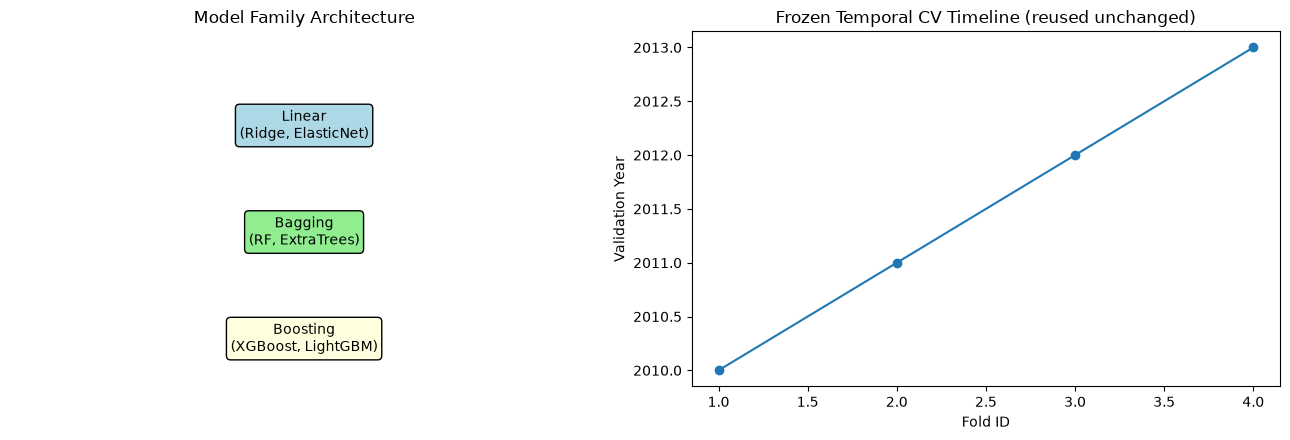

Analysis Question: 6 model x 4 fold = kac fit bekleniyor?
Hypothesis: Primary benchmark 24 fit; secondary (<=3 model) +12 fit; reproducibility reruns ek olarak.
Engineering Interpretation: Butun modeller ayni frozen fold/feature/target uzerinde karsilastirilacagi icin fair comparison saglanir.
Decision Impact: Bu registry, Section 10+'daki tum deneylerin referans cercevesidir.
Limitations: Fixed hyperparameters -- bu bir benchmark'tir, hyperparameter optimization degildir (Stage 10 kapsami).


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].text(0.5, 0.7, "Linear\n(Ridge, ElasticNet)", ha="center", bbox=dict(boxstyle="round", fc="lightblue"))
axes[0].text(0.5, 0.4, "Bagging\n(RF, ExtraTrees)", ha="center", bbox=dict(boxstyle="round", fc="lightgreen"))
axes[0].text(0.5, 0.1, "Boosting\n(XGBoost, LightGBM)", ha="center", bbox=dict(boxstyle="round", fc="lightyellow"))
axes[0].axis("off"); axes[0].set_title("Model Family Architecture")

timeline_folds = sorted(cv_fold_manifest_s05["Fold_ID"].unique())
axes[1].plot(timeline_folds, [2010, 2011, 2012, 2013], marker="o")
axes[1].set_xlabel("Fold ID"); axes[1].set_ylabel("Validation Year"); axes[1].set_title("Frozen Temporal CV Timeline (reused unchanged)")
plt.tight_layout()
plt.show()
print("Analysis Question: 6 model x 4 fold = kac fit bekleniyor?")
print("Hypothesis: Primary benchmark 24 fit; secondary (<=3 model) +12 fit; reproducibility reruns ek olarak.")
print("Engineering Interpretation: Butun modeller ayni frozen fold/feature/target uzerinde karsilastirilacagi icin fair comparison saglanir.")
print("Decision Impact: Bu registry, Section 10+'daki tum deneylerin referans cercevesidir.")
print("Limitations: Fixed hyperparameters -- bu bir benchmark'tir, hyperparameter optimization degildir (Stage 10 kapsami).")

In [9]:
model_registry = {
    "M01": {"name": "Ridge", "family": "Regularized Linear", "requires_scaling": True},
    "M02": {"name": "ElasticNet", "family": "Regularized Linear", "requires_scaling": True},
    "M03": {"name": "RandomForestRegressor", "family": "Bagging", "requires_scaling": False},
    "M04": {"name": "ExtraTreesRegressor", "family": "Bagging", "requires_scaling": False},
    "M05": {"name": "XGBRegressor", "family": "Gradient Boosting", "requires_scaling": False},
    "M06": {"name": "LGBMRegressor", "family": "Gradient Boosting", "requires_scaling": False},
}
with open(ARTIFACT_DIR / "stage09_model_registry.json", "w", encoding="utf-8") as f:
    json.dump(model_registry, f, indent=2, ensure_ascii=False)
print("Wrote stage09_model_registry.json")
pd.DataFrame(model_registry).T

Wrote stage09_model_registry.json


,name,family,requires_scaling
M01,Ridge,Regularized Linear,True
M02,ElasticNet,Regularized Linear,True
M03,RandomForestRegressor,Bagging,False
M04,ExtraTreesRegressor,Bagging,False
M05,XGBRegressor,Gradient Boosting,False
M06,LGBMRegressor,Gradient Boosting,False


## Section 06 — Fixed Estimator Configuration Policy

**Bu asama model benchmark'idir -- hyperparameter optimization DEGILDIR.** Asagidaki
degerler optimize edilmemistir; makul, reproducible, hesaplama acisindan sinirli
baslangic konfigurasyonlaridir. Stage 06'nin probe parametreleri (Ridge alpha=10.0,
RF n_estimators=80/max_depth=8/min_samples_leaf=3) **ayni degerlerle yeniden
kullanilmistir** -- ancak bu modeller Stage 09'un kendi benchmark protokolune
(farkli feature/preprocessing) **yeniden fit edilir**; eski Stage 06/07 probe
sonuclari burada DOGRUDAN kullanilmaz.

**Early Stopping Policy:** XGBoost/LightGBM icin **early stopping kullanilmiyor** --
sabit `n_estimators` ile calisiyoruz (frozen validation fold target'larinin booster
konfigurasyon secimine sizmasini onlemek icin).

In [10]:
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

MODEL_CFG = stage09_cfg["models"]


def get_estimator(model_id):
    if model_id == "M01":
        return Ridge(alpha=MODEL_CFG["ridge"]["alpha"])
    if model_id == "M02":
        return ElasticNet(alpha=MODEL_CFG["elastic_net"]["alpha"], l1_ratio=MODEL_CFG["elastic_net"]["l1_ratio"],
                           max_iter=MODEL_CFG["elastic_net"]["max_iter"], random_state=RANDOM_SEED)
    if model_id == "M03":
        c = MODEL_CFG["random_forest"]
        return RandomForestRegressor(n_estimators=c["n_estimators"], max_depth=c["max_depth"], min_samples_leaf=c["min_samples_leaf"], random_state=RANDOM_SEED, n_jobs=c["n_jobs"])
    if model_id == "M04":
        c = MODEL_CFG["extra_trees"]
        return ExtraTreesRegressor(n_estimators=c["n_estimators"], max_depth=c["max_depth"], min_samples_leaf=c["min_samples_leaf"], random_state=RANDOM_SEED, n_jobs=c["n_jobs"])
    if model_id == "M05":
        c = MODEL_CFG["xgboost"]
        return XGBRegressor(objective="reg:squarederror", n_estimators=c["n_estimators"], max_depth=c["max_depth"], learning_rate=c["learning_rate"],
                             subsample=c["subsample"], colsample_bytree=c["colsample_bytree"], reg_lambda=c["reg_lambda"], tree_method=c["tree_method"], random_state=RANDOM_SEED, n_jobs=c["n_jobs"])
    if model_id == "M06":
        c = MODEL_CFG["lightgbm"]
        return LGBMRegressor(objective="regression", n_estimators=c["n_estimators"], learning_rate=c["learning_rate"], num_leaves=c["num_leaves"],
                              min_child_samples=c["min_child_samples"], subsample=c["subsample"], subsample_freq=c["subsample_freq"],
                              colsample_bytree=c["colsample_bytree"], reg_lambda=c["reg_lambda"], random_state=RANDOM_SEED, n_jobs=c["n_jobs"], verbosity=-1)
    raise ValueError(f"Unknown model_id: {model_id}")


MODEL_NAMES = {"M01": "Ridge", "M02": "ElasticNet", "M03": "RandomForestRegressor", "M04": "ExtraTreesRegressor", "M05": "XGBRegressor", "M06": "LGBMRegressor"}
MODEL_FAMILIES = {"M01": "Regularized Linear", "M02": "Regularized Linear", "M03": "Bagging", "M04": "Bagging", "M05": "Gradient Boosting", "M06": "Gradient Boosting"}
REQUIRES_SCALING = {"M01": True, "M02": True, "M03": False, "M04": False, "M05": False, "M06": False}
print("Estimator factory defined for M01-M06. Scaling policy:", REQUIRES_SCALING)

Estimator factory defined for M01-M06. Scaling policy: {'M01': True, 'M02': True, 'M03': False, 'M04': False, 'M05': False, 'M06': False}


## Section 07 — Frozen CV Infrastructure (Model-Dependent Preprocessing)

**Learning Objective:** Stage 06'nin kabul ettigi preprocessing contract'ini (median
imputation, rare-category OneHot) model-ozgu scaling kuraliyla birlikte, leakage-safe
bir Pipeline icinde uygulamak.

In [11]:
def build_preprocessor(numeric_features, categorical_features, use_scaling):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if use_scaling:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)),
    ])
    return ColumnTransformer([("numeric", numeric_pipeline, numeric_features), ("categorical", categorical_pipeline, categorical_features)])


def get_fold_data(fold_id):
    manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
    train_keys = set(manifest.loc[manifest["Role"] == "Train", "Shipment_Key"])
    val_keys = set(manifest.loc[manifest["Role"] == "CV_Validation", "Shipment_Key"])
    train_df = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys) & shipment_view["Has_Numeric_Target"]]
    val_df = shipment_view[shipment_view[PRIMARY_KEY].isin(val_keys) & shipment_view["Has_Numeric_Target"]]
    return train_df, val_df


def compute_metrics(y_true, y_pred, y_train_for_threshold):
    abs_err = np.abs(y_true - y_pred)
    mae = float(np.mean(abs_err)); rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    median_ae = float(np.median(abs_err))
    wape = float(np.sum(abs_err) / np.sum(np.abs(y_true))) * 100 if np.sum(np.abs(y_true)) > 0 else np.nan
    bias = float(np.mean(y_pred - y_true))
    high_cost_threshold = np.quantile(y_train_for_threshold, 0.90)
    hc_mask = y_true >= high_cost_threshold
    high_cost_mae = float(np.mean(np.abs(y_true[hc_mask] - y_pred[hc_mask]))) if hc_mask.sum() > 0 else np.nan
    p90_ae = float(np.quantile(abs_err, 0.90)); p95_ae = float(np.quantile(abs_err, 0.95))
    return {"MAE": mae, "RMSE": rmse, "Median_AE": median_ae, "WAPE": wape, "Bias": bias,
            "High_Cost_MAE": high_cost_mae, "High_Cost_Count": int(hc_mask.sum()), "P90_Abs_Error": p90_ae, "P95_Abs_Error": p95_ae}


def run_model_cv(experiment_id, model_id, numeric_features, categorical_features, apply_nonneg_clip=False):
    fold_rows, oof_rows = [], []
    all_feats = numeric_features + categorical_features
    use_scaling = REQUIRES_SCALING[model_id]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
            train_df, val_df = get_fold_data(fold_id)
            X_train, y_train = train_df[all_feats], train_df["Freight_Cost_USD"].astype(float).values
            X_val, y_val = val_df[all_feats], val_df["Freight_Cost_USD"].astype(float).values

            preprocessor = build_preprocessor(numeric_features, categorical_features, use_scaling)
            pipeline = Pipeline([("preprocessor", preprocessor), ("model", get_estimator(model_id))])

            t0 = time.perf_counter()
            pipeline.fit(X_train, y_train)
            fit_time = time.perf_counter() - t0
            t0 = time.perf_counter()
            raw_preds_train = pipeline.predict(X_train)
            raw_preds_val = pipeline.predict(X_val)
            predict_time = time.perf_counter() - t0

            preds_val = np.clip(raw_preds_val, 0.0, None) if apply_nonneg_clip else raw_preds_val
            n_negative = int((raw_preds_val < 0).sum())
            assert not np.isnan(preds_val).any() and np.isfinite(preds_val).all(), f"{model_id} fold {fold_id}: invalid predictions!"

            train_mae = float(np.mean(np.abs(y_train - raw_preds_train)))
            metrics = compute_metrics(y_val, preds_val, y_train)
            fold_rows.append({
                "Experiment_ID": experiment_id, "Model_ID": model_id, "Model_Name": MODEL_NAMES[model_id], "Model_Family": MODEL_FAMILIES[model_id],
                "Fold_ID": int(fold_id), "Train_Count": len(train_df), "Validation_Count": len(val_df),
                "Training_MAE": train_mae, **metrics, "Generalization_Gap": metrics["MAE"] - train_mae,
                "N_Negative_Predictions": n_negative, "Fit_Time_s": fit_time, "Predict_Time_s": predict_time,
            })
            for key, actual, pred in zip(val_df[PRIMARY_KEY].values, y_val, preds_val):
                oof_rows.append({"Experiment_ID": experiment_id, "Model_ID": model_id, "Fold_ID": int(fold_id), "Shipment_Key": key, "Actual": actual, "Prediction": pred})
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows)


def pooled_mae(fold_df):
    return float((fold_df["MAE"] * fold_df["Validation_Count"]).sum() / fold_df["Validation_Count"].sum())


def pooled_metric(fold_df, col):
    return float((fold_df[col] * fold_df["Validation_Count"]).sum() / fold_df["Validation_Count"].sum())


print("CV infrastructure defined: build_preprocessor, get_fold_data, compute_metrics, run_model_cv, pooled_mae, pooled_metric.")

CV infrastructure defined: build_preprocessor, get_fold_data, compute_metrics, run_model_cv, pooled_mae, pooled_metric.


### Phase B — Minimal Smoke Test (Ridge, Fold 1)

In [12]:
_smoke_fold_df, _smoke_oof_df = run_model_cv("SMOKE", "M01", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)
print(_smoke_fold_df[["Fold_ID", "Train_Count", "Validation_Count", "MAE"]])
assert not _smoke_fold_df["MAE"].isna().any()
print("Smoke test PASSED (Ridge, all 4 folds).")

   Fold_ID  Train_Count  Validation_Count          MAE
0        1         1735               780  6911.382272
1        2         2515               776  7170.443516
2        3         3291               861  8904.462106
3        4         4152               835  8968.798154
Smoke test PASSED (Ridge, all 4 folds).


### Phase C — Multi-Family Smoke Test (one fold each)

In [13]:
for model_id in ["M01", "M02", "M03", "M04", "M05", "M06"]:
    train_df, val_df = get_fold_data(1)
    preprocessor = build_preprocessor(MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL, REQUIRES_SCALING[model_id])
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", get_estimator(model_id))])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipeline.fit(train_df[MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL], train_df["Freight_Cost_USD"].astype(float))
        preds = pipeline.predict(val_df[MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL])
    assert not np.isnan(preds).any() and np.isfinite(preds).all()
    print(f"{model_id} ({MODEL_NAMES[model_id]}): compatibility OK, sample prediction={preds[0]:.2f}")
print("\nMulti-family smoke test PASSED -- all 6 estimators compatible with the frozen pipeline.")

M01 (Ridge): compatibility OK, sample prediction=10888.15
M02 (ElasticNet): compatibility OK, sample prediction=8251.86


M03 (RandomForestRegressor): compatibility OK, sample prediction=6747.02


M04 (ExtraTreesRegressor): compatibility OK, sample prediction=10123.92


M05 (XGBRegressor): compatibility OK, sample prediction=9132.85
M06 (LGBMRegressor): compatibility OK, sample prediction=9271.73

Multi-family smoke test PASSED -- all 6 estimators compatible with the frozen pipeline.


## Section 08 — Regularized Linear Models: Ridge & ElasticNet

**Learning Objective:** Ridge (L2) ve ElasticNet (L1+L2) modellerinin matematiksel
davranisini ve freight cost prediction'daki sinirlamalarini anlamak.

### M01 — Ridge: $\min_\beta \sum_i (y_i - \hat y_i)^2 + \alpha\|\beta\|_2^2$

L2 regularization, katsayilari sifira **yaklastirir** ama tam sifirlamaz (coefficient
shrinkage). Correlated feature'lar arasinda agirligi "paylastirir" -- Stage 07'nin
Value grubu redundancy bulgusuyla tutarli bir davranis.

### M02 — ElasticNet: $\min_\beta \frac{1}{2n}\|y-X\beta\|_2^2 + \alpha\rho\|\beta\|_1 + \frac{\alpha(1-\rho)}{2}\|\beta\|_2^2$

L1+L2 kombinasyonu sparse coefficient'lar uretebilir. **Onemli:** Stage 07'de feature
selection yontemleri genel olarak No Selection'in gerisinde kalmisti -- ElasticNet'in
sparsity'si otomatik olarak daha iyi generalization anlamina gelmez.

### Freight Cost Hypothesis

Core feature'lar (Qty/Value Sum, Shipment Mode, INCOTERM, Country, Product Group) ile
target arasinda guclu linear iliski varsa Ridge yeterli olabilir; ancak nonlinear
interactions (farkli transport mode'lari icin farkli maliyet egimleri) ve heavy-tailed
target bu varsayimi sinirlayabilir.

**Target Transformation Restriction:** Stage 06'da Ridge+log-target instability
(D-039) tespit edildi -- bu notebookta log-target **kullanilmamaktadir**, original
scale target policy uygulanir.

In [14]:
m01_fold_df, m01_oof_df = run_model_cv("PRIMARY", "M01", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)
m02_fold_df, m02_oof_df = run_model_cv("PRIMARY", "M02", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)

print("M01 (Ridge) Pooled MAE:     ", round(pooled_mae(m01_fold_df), 2))
print("M02 (ElasticNet) Pooled MAE:", round(pooled_mae(m02_fold_df), 2))
print("\nM01 negative predictions (raw, before any clipping):", m01_fold_df["N_Negative_Predictions"].sum())
print("M02 negative predictions (raw, before any clipping):", m02_fold_df["N_Negative_Predictions"].sum())

M01 (Ridge) Pooled MAE:      8029.16
M02 (ElasticNet) Pooled MAE: 7993.6

M01 negative predictions (raw, before any clipping): 96
M02 negative predictions (raw, before any clipping): 0


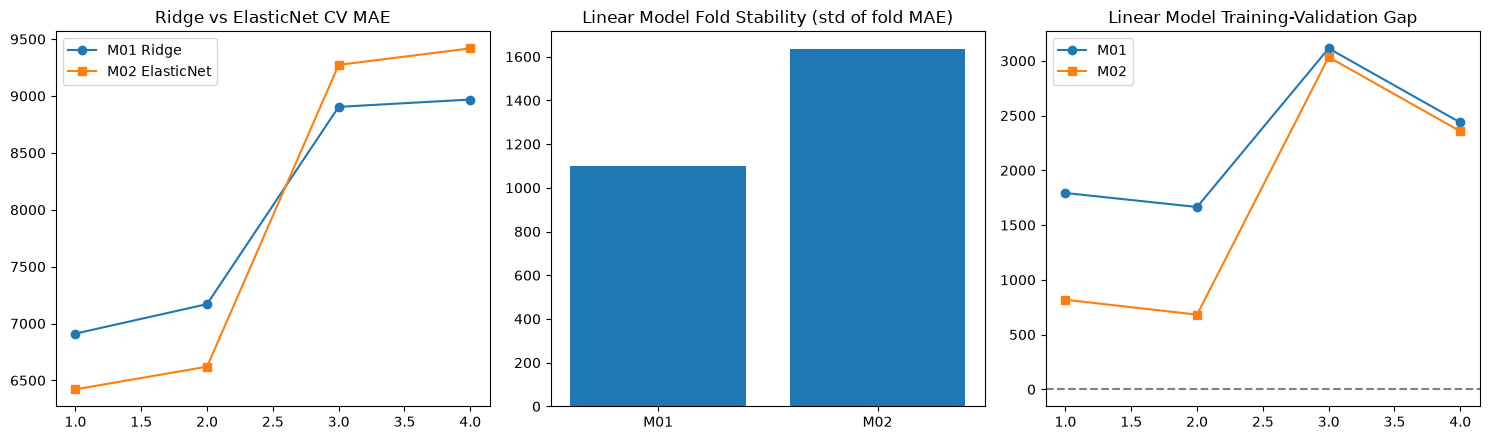

Analysis Question: ElasticNet, Ridge'e gore anlamli fayda sagliyor mu?
Statistical Observation: Pooled MAE -- M01=8029.16, M02=7993.60.
Engineering Interpretation: Fark kucukse, ElasticNet'in sparsity avantaji bu feature setinde (6 feature, zaten kucuk) somut bir kazanca donusmeyebilir.
Decision Impact: Section 14 Six-Model Benchmark'a girdi saglar.
Limitations: Henuz final winner ilan edilmedi -- bu sadece linear model family icin ilk kanittir.


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(m01_fold_df["Fold_ID"], m01_fold_df["MAE"], marker="o", label="M01 Ridge")
axes[0].plot(m02_fold_df["Fold_ID"], m02_fold_df["MAE"], marker="s", label="M02 ElasticNet")
axes[0].set_title("Ridge vs ElasticNet CV MAE"); axes[0].legend()

axes[1].bar(["M01", "M02"], [m01_fold_df["MAE"].std(), m02_fold_df["MAE"].std()])
axes[1].set_title("Linear Model Fold Stability (std of fold MAE)")

axes[2].plot(m01_fold_df["Fold_ID"], m01_fold_df["Generalization_Gap"], marker="o", label="M01")
axes[2].plot(m02_fold_df["Fold_ID"], m02_fold_df["Generalization_Gap"], marker="s", label="M02")
axes[2].axhline(0, color="gray", linestyle="--")
axes[2].set_title("Linear Model Training-Validation Gap"); axes[2].legend()
plt.tight_layout()
plt.show()
print("Analysis Question: ElasticNet, Ridge'e gore anlamli fayda sagliyor mu?")
print(f"Statistical Observation: Pooled MAE -- M01={pooled_mae(m01_fold_df):.2f}, M02={pooled_mae(m02_fold_df):.2f}.")
print("Engineering Interpretation: Fark kucukse, ElasticNet'in sparsity avantaji bu feature setinde (6 feature, zaten kucuk) somut bir kazanca donusmeyebilir.")
print("Decision Impact: Section 14 Six-Model Benchmark'a girdi saglar.")
print("Limitations: Henuz final winner ilan edilmedi -- bu sadece linear model family icin ilk kanittir.")

## Section 09 — Bagging & Randomized Trees: Random Forest & ExtraTrees

**Learning Objective:** Random Forest ve ExtraTrees'in nonlinear iliskileri nasil
yakaladigini ve variance reduction mekanizmasini anlamak.

### Ensemble Prediction

$$\hat y(x) = \frac{1}{T}\sum_{t=1}^{T} f_t(x)$$

$T$: ensemble'daki agac sayisi. Her agac, bootstrap sample (RF) veya tum training
set (ExtraTrees default) uzerinde, random feature subset ile egitilir.

### Random Forest vs ExtraTrees

RF, her split icin **en iyi** threshold'u arar (sinirli feature subset icinde);
ExtraTrees, split threshold'larini da **rastgele** secer -- bu, bias'i hafifce
artirirken variance'i daha fazla dusurebilir. **Onemli:** scikit-learn'un
`bootstrap` default degeri iki estimator icin **farklidir** (RF: True, ExtraTrees:
False) -- bu, iki modelin varsayilan davranisini etkiler.

### Freight Cost Hypothesis

Shipment Mode/INCOTERM interactions, numeric threshold'lar (orn. Line_Item_Value_Sum'un
belirli esiklerin ustunde farkli maliyet rejimine girmesi) nonlinear modellerden fayda
saglayabilir.

In [16]:
import sklearn.ensemble
print("RandomForestRegressor default bootstrap:", sklearn.ensemble.RandomForestRegressor().bootstrap)
print("ExtraTreesRegressor default bootstrap:   ", sklearn.ensemble.ExtraTreesRegressor().bootstrap)

m03_fold_df, m03_oof_df = run_model_cv("PRIMARY", "M03", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)
m04_fold_df, m04_oof_df = run_model_cv("PRIMARY", "M04", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)

print("\nM03 (Random Forest) Pooled MAE:", round(pooled_mae(m03_fold_df), 2))
print("M04 (ExtraTrees) Pooled MAE:    ", round(pooled_mae(m04_fold_df), 2))

RandomForestRegressor default bootstrap: True
ExtraTreesRegressor default bootstrap:    False



M03 (Random Forest) Pooled MAE: 6151.9
M04 (ExtraTrees) Pooled MAE:     5880.35


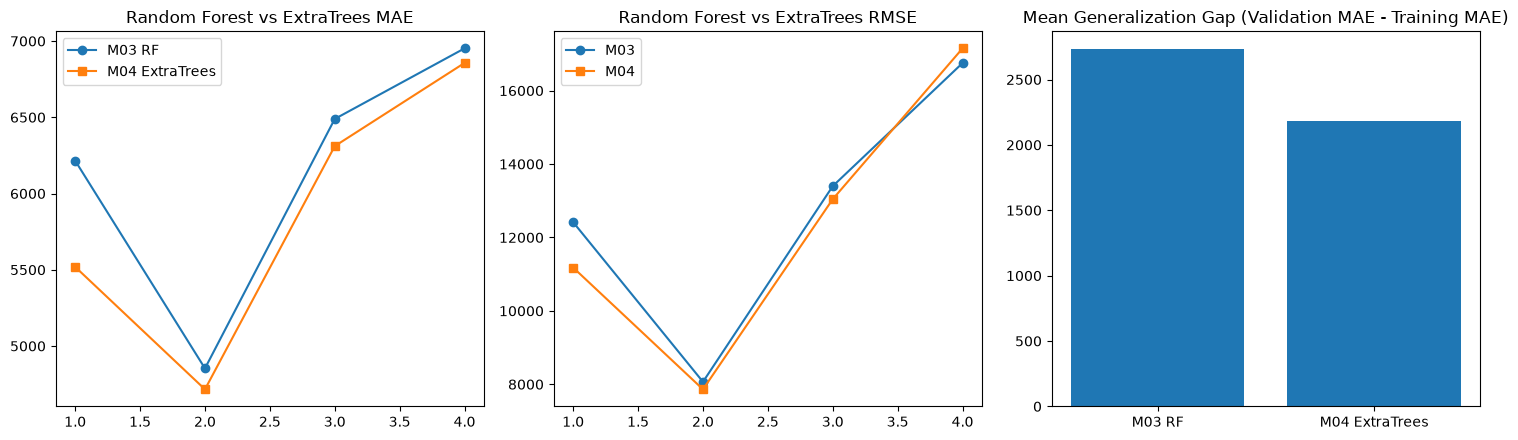

Analysis Question: ExtraTrees daha dusuk variance (daha stabil fold-fold performans) sagliyor mu?
Statistical Observation: Pooled MAE -- M03=6151.90 (std=902.2), M04=5880.35 (std=934.7).
Engineering Interpretation: Dusuk training MAE, otomatik olarak daha iyi validation performance anlamina gelmez (Generalization Gap grafiginde gorulebilir).
Decision Impact: Section 14 Six-Model Benchmark'a girdi saglar.
Limitations: Temporal distribution shift de gap'e katkida bulunabilir -- gap tek basina overfitting kaniti degildir.


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(m03_fold_df["Fold_ID"], m03_fold_df["MAE"], marker="o", label="M03 RF")
axes[0].plot(m04_fold_df["Fold_ID"], m04_fold_df["MAE"], marker="s", label="M04 ExtraTrees")
axes[0].set_title("Random Forest vs ExtraTrees MAE"); axes[0].legend()

axes[1].plot(m03_fold_df["Fold_ID"], m03_fold_df["RMSE"], marker="o", label="M03")
axes[1].plot(m04_fold_df["Fold_ID"], m04_fold_df["RMSE"], marker="s", label="M04")
axes[1].set_title("Random Forest vs ExtraTrees RMSE"); axes[1].legend()

axes[2].bar(["M03 RF", "M04 ExtraTrees"], [m03_fold_df["Generalization_Gap"].mean(), m04_fold_df["Generalization_Gap"].mean()])
axes[2].set_title("Mean Generalization Gap (Validation MAE - Training MAE)")
plt.tight_layout()
plt.show()
print("Analysis Question: ExtraTrees daha dusuk variance (daha stabil fold-fold performans) sagliyor mu?")
print(f"Statistical Observation: Pooled MAE -- M03={pooled_mae(m03_fold_df):.2f} (std={m03_fold_df['MAE'].std():.1f}), M04={pooled_mae(m04_fold_df):.2f} (std={m04_fold_df['MAE'].std():.1f}).")
print("Engineering Interpretation: Dusuk training MAE, otomatik olarak daha iyi validation performance anlamina gelmez (Generalization Gap grafiginde gorulebilir).")
print("Decision Impact: Section 14 Six-Model Benchmark'a girdi saglar.")
print("Limitations: Temporal distribution shift de gap'e katkida bulunabilir -- gap tek basina overfitting kaniti degildir.")

## Section 10 — Gradient Boosting: XGBoost & LightGBM

**Learning Objective:** Sequential boosting'in bagging'den (RF/ExtraTrees) farkini
anlamak.

### Additive Model

$$F_m(x) = F_{m-1}(x) + \eta h_m(x)$$

$F_m(x)$: iterasyon $m$ sonrasi model, $h_m(x)$: yeni learner (residual'lari duzeltmeye
calisir), $\eta$: learning rate. Bagging'in **parallel, bagimsiz** agaclarindan farkli
olarak, boosting agaclari **sirali** ve **birbirinin hatasini duzeltecek sekilde**
egitilir.

### XGBoost vs LightGBM

XGBoost: level-wise (depth-limited) agac buyutme, histogram-based split (`tree_method=
"hist"`). LightGBM: leaf-wise agac buyutme (`num_leaves` ile kontrol edilir), genellikle
daha hizli ama daha kolay overfit edebilir. **Iki algoritma arasinda teorik bir winner
ilan edilmemektedir** -- performans dataset size, feature representation, hyperparameters
ve temporal data distribution'a baglidir.

**Early Stopping Policy:** Bu primary benchmark'ta **early stopping kullanilmamaktadir**
-- sabit `n_estimators=200` ile calisiliyor, boosting'in frozen validation fold
target'larina erisimi yoktur.

**Native Categorical Handling:** LightGBM bazi kosullarda native categorical destekler,
ancak bu primary benchmark **Stage 06/07'nin kabul ettigi OneHot preprocessing
contract'ini** kullanir -- model-specific input representation degisikligi, model family
etkisiyle input representation etkisini birbirine karistirir.

In [18]:
m05_fold_df, m05_oof_df = run_model_cv("PRIMARY", "M05", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)
m06_fold_df, m06_oof_df = run_model_cv("PRIMARY", "M06", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)

print("M05 (XGBoost) Pooled MAE:  ", round(pooled_mae(m05_fold_df), 2))
print("M06 (LightGBM) Pooled MAE: ", round(pooled_mae(m06_fold_df), 2))

M05 (XGBoost) Pooled MAE:   5808.51
M06 (LightGBM) Pooled MAE:  6236.25


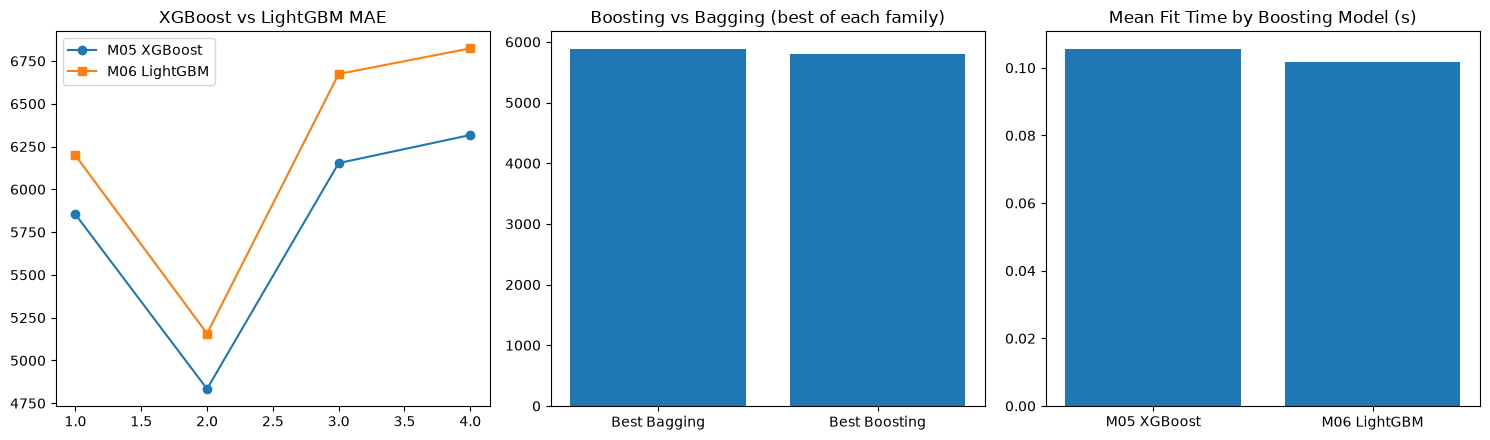

Analysis Question: Boosting, bagging'e gore anlamli iyilesme sagliyor mu?
Statistical Observation: Best Bagging=5880.35, Best Boosting=5808.51.
Engineering Interpretation: XGBoost/LightGBM arasindaki fark fold'lar arasinda tutarli mi, Section 14'te paired comparison ile incelenecek.
Decision Impact: Section 18 Model Shortlisting'e girdi saglar.
Limitations: Sabit n_estimators/learning_rate ile calisildi -- bu bir hyperparameter optimization degil, ilk-kanit benchmark'tir.


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(m05_fold_df["Fold_ID"], m05_fold_df["MAE"], marker="o", label="M05 XGBoost")
axes[0].plot(m06_fold_df["Fold_ID"], m06_fold_df["MAE"], marker="s", label="M06 LightGBM")
axes[0].set_title("XGBoost vs LightGBM MAE"); axes[0].legend()

bagging_best_mae = min(pooled_mae(m03_fold_df), pooled_mae(m04_fold_df))
boosting_best_mae = min(pooled_mae(m05_fold_df), pooled_mae(m06_fold_df))
axes[1].bar(["Best Bagging", "Best Boosting"], [bagging_best_mae, boosting_best_mae])
axes[1].set_title("Boosting vs Bagging (best of each family)")

axes[2].bar(["M05 XGBoost", "M06 LightGBM"], [m05_fold_df["Fit_Time_s"].mean(), m06_fold_df["Fit_Time_s"].mean()])
axes[2].set_title("Mean Fit Time by Boosting Model (s)")
plt.tight_layout()
plt.show()
print("Analysis Question: Boosting, bagging'e gore anlamli iyilesme sagliyor mu?")
print(f"Statistical Observation: Best Bagging={bagging_best_mae:.2f}, Best Boosting={boosting_best_mae:.2f}.")
print("Engineering Interpretation: XGBoost/LightGBM arasindaki fark fold'lar arasinda tutarli mi, Section 14'te paired comparison ile incelenecek.")
print("Decision Impact: Section 18 Model Shortlisting'e girdi saglar.")
print("Limitations: Sabit n_estimators/learning_rate ile calisildi -- bu bir hyperparameter optimization degil, ilk-kanit benchmark'tir.")

## Section 11 — Six-Model Benchmark & Statistical Evaluation

**Main Question:** Alti modelden hangileri, accepted B4 business baseline'ina gore
gercek ve tutarli performance improvement sagliyor?

### Fair Comparison Gate

B4/B1 ve candidate model predictions **ayni validation shipment keys** uzerinde
olmalidir.

In [20]:
all_model_fold_results = pd.concat([m01_fold_df, m02_fold_df, m03_fold_df, m04_fold_df, m05_fold_df, m06_fold_df], ignore_index=True)
all_model_oof_results = pd.concat([m01_oof_df, m02_oof_df, m03_oof_df, m04_oof_df, m05_oof_df, m06_oof_df], ignore_index=True)

# Fair comparison gate.
model_keys = set(m01_oof_df["Shipment_Key"].unique())
b4_keys = set(b4_oof["Shipment_Key"].unique())
assert model_keys == b4_keys, "FAIR COMPARISON GATE FAILED: model vs B4 evaluation population mismatch."
print("Fair Comparison Gate: PASSED -- models and B1/B4 share the identical", len(model_keys), "validation shipments.")

all_model_fold_results.to_csv(ARTIFACT_DIR / "stage09_cv_results.csv", index=False)
all_model_oof_results.to_csv(ARTIFACT_DIR / "stage09_oof_predictions.csv", index=False)
print("Wrote stage09_cv_results.csv --", len(all_model_fold_results), "rows")
print("Wrote stage09_oof_predictions.csv --", len(all_model_oof_results), "rows")

training_diagnostics = all_model_fold_results[["Model_ID", "Fold_ID", "Train_Count", "Validation_Count", "Training_MAE", "MAE", "Generalization_Gap"]].copy()
training_diagnostics.to_csv(ARTIFACT_DIR / "stage09_training_diagnostics.csv", index=False)
print("Wrote stage09_training_diagnostics.csv")

prediction_bias_analysis = all_model_fold_results[["Model_ID", "Fold_ID", "Bias", "N_Negative_Predictions"]].copy()
prediction_bias_analysis.to_csv(ARTIFACT_DIR / "stage09_prediction_bias_analysis.csv", index=False)
print("Wrote stage09_prediction_bias_analysis.csv")

experiment_registry = {
    "primary_benchmark": {"models": list(MODEL_NAMES.keys()), "feature_set": "Minimal Core", "folds": sorted(cv_fold_manifest_s05["Fold_ID"].unique().tolist())},
    "random_seed": RANDOM_SEED, "cv_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
}
with open(ARTIFACT_DIR / "stage09_experiment_registry.json", "w", encoding="utf-8") as f:
    json.dump(experiment_registry, f, indent=2, ensure_ascii=False)
print("Wrote stage09_experiment_registry.json")

oof_keys = set(all_model_oof_results["Shipment_Key"].unique())
train_keys_all = set(split_manifest_s05.loc[split_manifest_s05["Split"] == "Train", "Shipment_Key"])
assert oof_keys.issubset(train_keys_all), "CRITICAL: OOF predictions leaked outside Training split!"
print("Leakage audit: all OOF shipment keys confirmed within Training split only -- OK")

Fair Comparison Gate: PASSED -- models and B1/B4 share the identical 3252 validation shipments.
Wrote stage09_cv_results.csv -- 24 rows
Wrote stage09_oof_predictions.csv -- 19512 rows
Wrote stage09_training_diagnostics.csv
Wrote stage09_prediction_bias_analysis.csv
Wrote stage09_experiment_registry.json
Leakage audit: all OOF shipment keys confirmed within Training split only -- OK


In [21]:
comparison_rows = []
model_fold_dfs = {"M01": m01_fold_df, "M02": m02_fold_df, "M03": m03_fold_df, "M04": m04_fold_df, "M05": m05_fold_df, "M06": m06_fold_df}
for model_id, fold_df in model_fold_dfs.items():
    p_mae = pooled_mae(fold_df)
    comparison_rows.append({
        "Model_ID": model_id, "Model_Name": MODEL_NAMES[model_id], "Model_Family": MODEL_FAMILIES[model_id], "Feature_Set": "Minimal Core",
        "Pooled_MAE_USD": p_mae, "Mean_Fold_MAE_USD": fold_df["MAE"].mean(), "Std_Fold_MAE_USD": fold_df["MAE"].std(),
        "Pooled_RMSE_USD": pooled_metric(fold_df, "RMSE"), "WAPE_Percent": pooled_metric(fold_df, "WAPE"), "Bias_USD": pooled_metric(fold_df, "Bias"),
        "High_Cost_MAE_USD": fold_df["High_Cost_MAE"].mean(), "P90_Absolute_Error_USD": fold_df["P90_Abs_Error"].mean(),
        "Mean_Fit_Time_s": fold_df["Fit_Time_s"].mean(), "Mean_Predict_Time_s": fold_df["Predict_Time_s"].mean(),
        "Improvement_vs_B4_Percent": (B4_POOLED_MAE - p_mae) / B4_POOLED_MAE * 100, "Improvement_vs_B1_Percent": (B1_POOLED_MAE - p_mae) / B1_POOLED_MAE * 100,
    })
model_comparison = pd.DataFrame(comparison_rows).sort_values("Pooled_MAE_USD")
model_comparison.to_csv(ARTIFACT_DIR / "stage09_model_comparison.csv", index=False)
print("Wrote stage09_model_comparison.csv")
model_comparison

Wrote stage09_model_comparison.csv


,Model_ID,Model_Name,Model_Family,Feature_Set,Pooled_MAE_USD,Mean_Fold_MAE_USD,Std_Fold_MAE_USD,Pooled_RMSE_USD,WAPE_Percent,Bias_USD,High_Cost_MAE_USD,P90_Absolute_Error_USD,Mean_Fit_Time_s,Mean_Predict_Time_s,Improvement_vs_B4_Percent,Improvement_vs_B1_Percent
4,M05,XGBRegressor,Gradient Boosting,Minimal Core,5808.511008,5789.343563,665.483939,12015.812942,49.582669,-1226.125930,17260.266686,13113.460036,0.105506,0.013107,33.193700,36.214619
3,M04,ExtraTreesRegressor,Bagging,Minimal Core,5880.354694,5850.481076,934.692789,12414.328955,49.785737,-1519.743266,18353.309731,13118.662603,0.154657,0.082522,32.367393,35.425677
2,M03,RandomForestRegressor,Bagging,Minimal Core,6151.895901,6127.373695,902.232385,12750.824384,52.403058,-1353.051634,18630.482879,14159.699505,0.187900,0.077940,29.244275,32.443784
5,M06,LGBMRegressor,Gradient Boosting,Minimal Core,6236.254959,6213.152797,752.965045,12597.621489,53.155510,-1332.627611,17865.127929,14911.566854,0.101670,0.030949,28.274024,31.517406
1,M02,ElasticNet,Regularized Linear,Minimal Core,7993.597219,7933.491254,1634.111088,15108.160653,66.956008,-2120.351670,25106.578945,15450.276017,0.012137,0.007099,8.062039,12.219389
0,M01,Ridge,Regularized Linear,Minimal Core,8029.160724,7988.771512,1099.904506,14824.531818,67.824388,-1614.564230,23215.266944,15696.679248,0.013083,0.008500,7.653007,11.828853


In [22]:
baseline_improvement_rows = []
for model_id, fold_df in model_fold_dfs.items():
    p_mae = pooled_mae(fold_df)
    baseline_improvement_rows.append({"Model_ID": model_id, "Pooled_MAE": p_mae, "Delta_vs_B4": p_mae - B4_POOLED_MAE, "Delta_vs_B1": p_mae - B1_POOLED_MAE,
                                       "Improvement_vs_B4_Pct": (B4_POOLED_MAE - p_mae) / B4_POOLED_MAE * 100, "Improvement_vs_B1_Pct": (B1_POOLED_MAE - p_mae) / B1_POOLED_MAE * 100})
baseline_improvements = pd.DataFrame(baseline_improvement_rows)
baseline_improvements.to_csv(ARTIFACT_DIR / "stage09_baseline_improvements.csv", index=False)
print("Wrote stage09_baseline_improvements.csv")
baseline_improvements.sort_values("Pooled_MAE")

Wrote stage09_baseline_improvements.csv


,Model_ID,Pooled_MAE,Delta_vs_B4,Delta_vs_B1,Improvement_vs_B4_Pct,Improvement_vs_B1_Pct
4,M05,5808.511008,-2886.044699,-3297.824819,33.193700,36.214619
3,M04,5880.354694,-2814.201014,-3225.981133,32.367393,35.425677
2,M03,6151.895901,-2542.659806,-2954.439926,29.244275,32.443784
5,M06,6236.254959,-2458.300748,-2870.080868,28.274024,31.517406
1,M02,7993.597219,-700.958488,-1112.738608,8.062039,12.219389
0,M01,8029.160724,-665.394984,-1077.175104,7.653007,11.828853


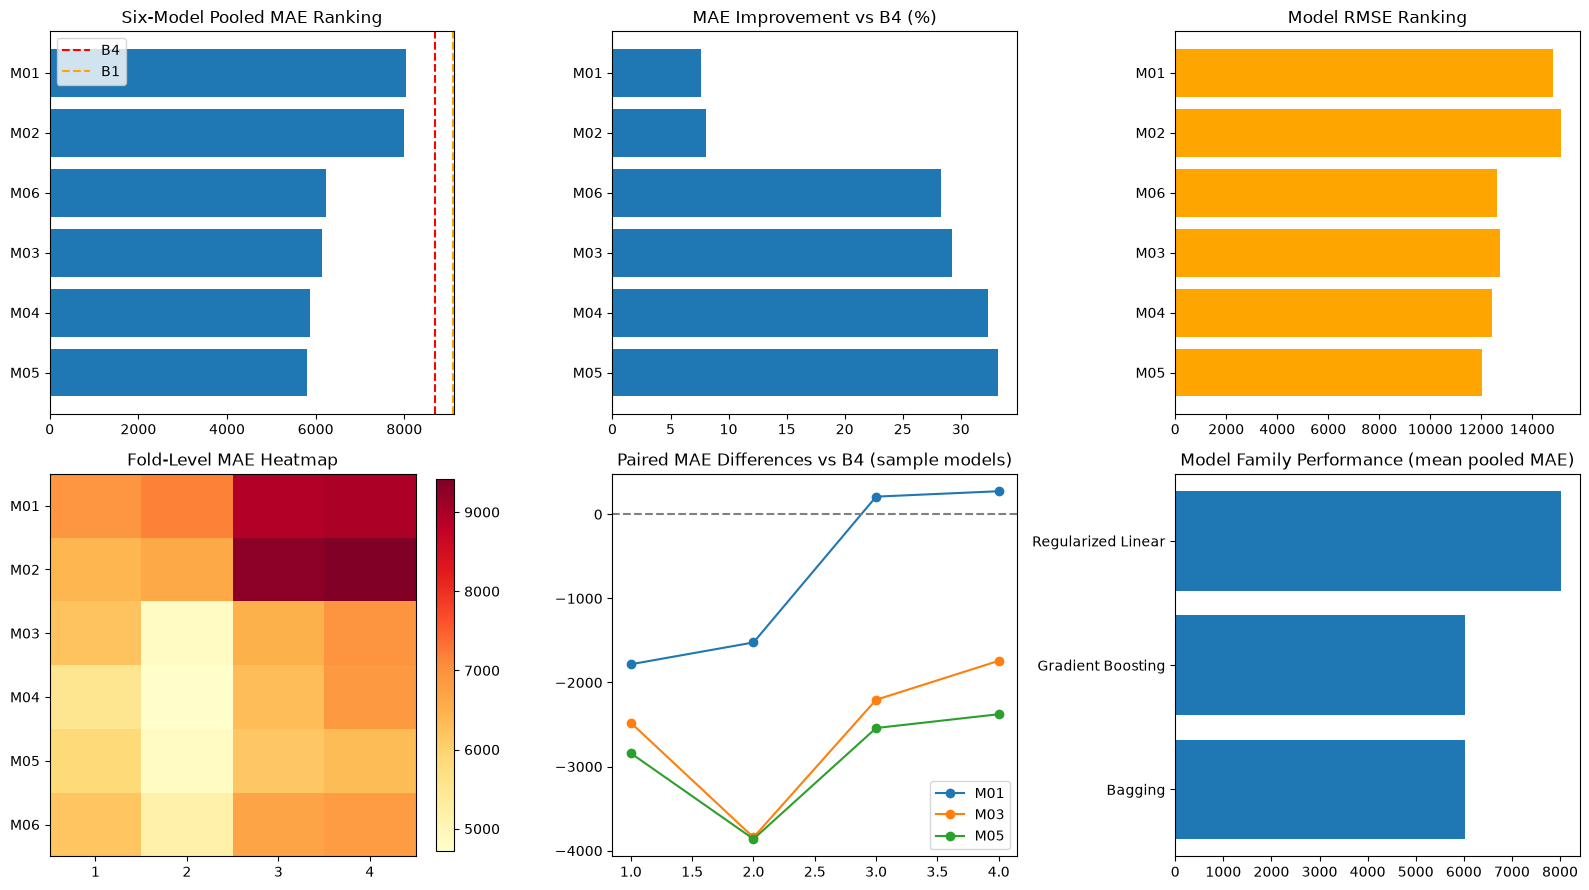

Analysis Question: Hangi model(ler) B4'e gore gercek ve tutarli iyilesme sagliyor?
Statistical Observation: En iyi -- M05 (5808.51 USD, B4'e gore %33.2 iyilesme).
Engineering Interpretation: Fold-level heatmap, iyilesmenin TUM fold'larda tutarli olup olmadigini gosterir -- tek fold'a bagli bir kazanc guvenilir degildir.
Decision Impact: Section 18 Model Shortlisting'e temel olusturur.
Limitations: 4 (kismen bagimli) fold -- naive independent-fold p-value hesaplanmadi; yon tutarliligi pratik kanit olarak kullanildi.


In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sorted_cmp = model_comparison.sort_values("Pooled_MAE_USD")
axes[0, 0].barh(sorted_cmp["Model_ID"], sorted_cmp["Pooled_MAE_USD"])
axes[0, 0].axvline(B4_POOLED_MAE, color="red", linestyle="--", label="B4"); axes[0, 0].axvline(B1_POOLED_MAE, color="orange", linestyle="--", label="B1")
axes[0, 0].set_title("Six-Model Pooled MAE Ranking"); axes[0, 0].legend()

axes[0, 1].barh(sorted_cmp["Model_ID"], sorted_cmp["Improvement_vs_B4_Percent"])
axes[0, 1].axvline(0, color="gray", linestyle="--")
axes[0, 1].set_title("MAE Improvement vs B4 (%)")

axes[0, 2].barh(sorted_cmp["Model_ID"], sorted_cmp["Pooled_RMSE_USD"], color="orange")
axes[0, 2].set_title("Model RMSE Ranking")

fold_pivot = all_model_fold_results.pivot(index="Model_ID", columns="Fold_ID", values="MAE")
im = axes[1, 0].imshow(fold_pivot.values, cmap="YlOrRd", aspect="auto")
axes[1, 0].set_yticks(range(len(fold_pivot.index))); axes[1, 0].set_yticklabels(fold_pivot.index)
axes[1, 0].set_xticks(range(len(fold_pivot.columns))); axes[1, 0].set_xticklabels(fold_pivot.columns)
axes[1, 0].set_title("Fold-Level MAE Heatmap"); plt.colorbar(im, ax=axes[1, 0], fraction=0.046)

for model_id in ["M01", "M03", "M05"]:
    delta = model_fold_dfs[model_id].set_index("Fold_ID")["MAE"] - B4_POOLED_MAE
    axes[1, 1].plot(delta.index, delta.values, marker="o", label=model_id)
axes[1, 1].axhline(0, color="gray", linestyle="--")
axes[1, 1].set_title("Paired MAE Differences vs B4 (sample models)"); axes[1, 1].legend()

family_avg = model_comparison.groupby("Model_Family")["Pooled_MAE_USD"].mean().sort_values()
axes[1, 2].barh(family_avg.index, family_avg.values)
axes[1, 2].set_title("Model Family Performance (mean pooled MAE)")
plt.tight_layout()
plt.show()
print("Analysis Question: Hangi model(ler) B4'e gore gercek ve tutarli iyilesme sagliyor?")
print(f"Statistical Observation: En iyi -- {sorted_cmp.iloc[0]['Model_ID']} ({sorted_cmp.iloc[0]['Pooled_MAE_USD']:.2f} USD, B4'e gore %{sorted_cmp.iloc[0]['Improvement_vs_B4_Percent']:.1f} iyilesme).")
print("Engineering Interpretation: Fold-level heatmap, iyilesmenin TUM fold'larda tutarli olup olmadigini gosterir -- tek fold'a bagli bir kazanc guvenilir degildir.")
print("Decision Impact: Section 18 Model Shortlisting'e temel olusturur.")
print("Limitations: 4 (kismen bagimli) fold -- naive independent-fold p-value hesaplanmadi; yon tutarliligi pratik kanit olarak kullanildi.")

In [24]:
pairwise_rows = []
for a, b, label in [("M01", "M02", "Ridge vs ElasticNet"), ("M03", "M04", "RF vs ExtraTrees"), ("M05", "M06", "XGBoost vs LightGBM")]:
    delta = model_fold_dfs[a].set_index("Fold_ID")["MAE"] - model_fold_dfs[b].set_index("Fold_ID")["MAE"]
    pairwise_rows.append({"Comparison": label, "Mean_Delta": delta.mean(), "Folds_A_Better": int((delta < 0).sum()), "Folds_B_Better": int((delta > 0).sum())})
best_linear = model_comparison[model_comparison["Model_Family"] == "Regularized Linear"].sort_values("Pooled_MAE_USD").iloc[0]["Model_ID"]
best_bagging = model_comparison[model_comparison["Model_Family"] == "Bagging"].sort_values("Pooled_MAE_USD").iloc[0]["Model_ID"]
best_boosting = model_comparison[model_comparison["Model_Family"] == "Gradient Boosting"].sort_values("Pooled_MAE_USD").iloc[0]["Model_ID"]
delta = model_fold_dfs[best_linear].set_index("Fold_ID")["MAE"] - model_fold_dfs[best_bagging].set_index("Fold_ID")["MAE"]
pairwise_rows.append({"Comparison": f"Best Linear ({best_linear}) vs Best Tree-Ensemble ({best_bagging})", "Mean_Delta": delta.mean(), "Folds_A_Better": int((delta < 0).sum()), "Folds_B_Better": int((delta > 0).sum())})
delta = model_fold_dfs[best_bagging].set_index("Fold_ID")["MAE"] - model_fold_dfs[best_boosting].set_index("Fold_ID")["MAE"]
pairwise_rows.append({"Comparison": f"Best Bagging ({best_bagging}) vs Best Boosting ({best_boosting})", "Mean_Delta": delta.mean(), "Folds_A_Better": int((delta < 0).sum()), "Folds_B_Better": int((delta > 0).sum())})
paired_fold_comparisons = pd.DataFrame(pairwise_rows)
paired_fold_comparisons.to_csv(ARTIFACT_DIR / "stage09_paired_fold_comparisons.csv", index=False)
print("Wrote stage09_paired_fold_comparisons.csv")
paired_fold_comparisons

Wrote stage09_paired_fold_comparisons.csv


,Comparison,Mean_Delta,Folds_A_Better,Folds_B_Better
0,Ridge vs ElasticNet,55.280259,2,2
1,RF vs ExtraTrees,276.892619,0,4
2,XGBoost vs LightGBM,-423.809235,4,0
3,Best Linear (M02) vs Best Tree-Ensemble (M04),2083.010178,0,4
4,Best Bagging (M04) vs Best Boosting (M05),61.137513,2,2


## Section 12 — Secondary Feature Set Experiment (Extended Eligible, Exploratory)

**Secondary Question:** Extended Eligible feature set, primary benchmark'ta secilen
sinirli sayida model uzerinde additional predictive benefit sagliyor mu?

**Mandatory Controls:** Ayni frozen CV, ayni estimator hyperparameters (DEGISTIRILMEDI),
ayni target/metric tanimlari -- **sadece feature set degisiyor**. Bu secim primary CV
sonuclarina dayandigi icin **exploratory** olarak etiketlenmistir (adaptive selection
riski tasir).

In [25]:
SECONDARY_CANDIDATES = [best_linear, best_bagging, best_boosting]
print("Secondary experiment candidates (best of each family from primary benchmark):", SECONDARY_CANDIDATES)

secondary_rows = []
for model_id in SECONDARY_CANDIDATES:
    core_fold_df = model_fold_dfs[model_id]
    ext_fold_df, ext_oof_df = run_model_cv("SECONDARY_EXTENDED", model_id, EXTENDED_NUMERIC, EXTENDED_CATEGORICAL)
    secondary_rows.append({
        "Model_ID": model_id, "Core_MAE": pooled_mae(core_fold_df), "Extended_MAE": pooled_mae(ext_fold_df),
        "MAE_Difference": pooled_mae(ext_fold_df) - pooled_mae(core_fold_df),
        "Core_High_Cost_MAE": core_fold_df["High_Cost_MAE"].mean(), "Extended_High_Cost_MAE": ext_fold_df["High_Cost_MAE"].mean(),
        "Core_Fit_Time_s": core_fold_df["Fit_Time_s"].mean(), "Extended_Fit_Time_s": ext_fold_df["Fit_Time_s"].mean(),
        "Core_Feature_Count": len(MINIMAL_CORE_NUMERIC) + len(MINIMAL_CORE_CATEGORICAL), "Extended_Feature_Count": len(EXTENDED_NUMERIC) + len(EXTENDED_CATEGORICAL),
    })
feature_set_sensitivity = pd.DataFrame(secondary_rows)
feature_set_sensitivity.to_csv(ARTIFACT_DIR / "stage09_feature_set_sensitivity.csv", index=False)
print("Wrote stage09_feature_set_sensitivity.csv")
feature_set_sensitivity

Secondary experiment candidates (best of each family from primary benchmark): ['M02', 'M04', 'M05']


Wrote stage09_feature_set_sensitivity.csv


,Model_ID,Core_MAE,Extended_MAE,MAE_Difference,Core_High_Cost_MAE,Extended_High_Cost_MAE,Core_Fit_Time_s,Extended_Fit_Time_s,Core_Feature_Count,Extended_Feature_Count
0,M02,7993.597219,7947.124922,-46.472297,25106.578945,24683.202604,0.012137,0.017180,6,15
1,M04,5880.354694,5924.494052,44.139358,18353.309731,18539.292477,0.154657,0.186822,6,15
2,M05,5808.511008,5938.732288,130.221280,17260.266686,17405.029589,0.105506,0.124490,6,15


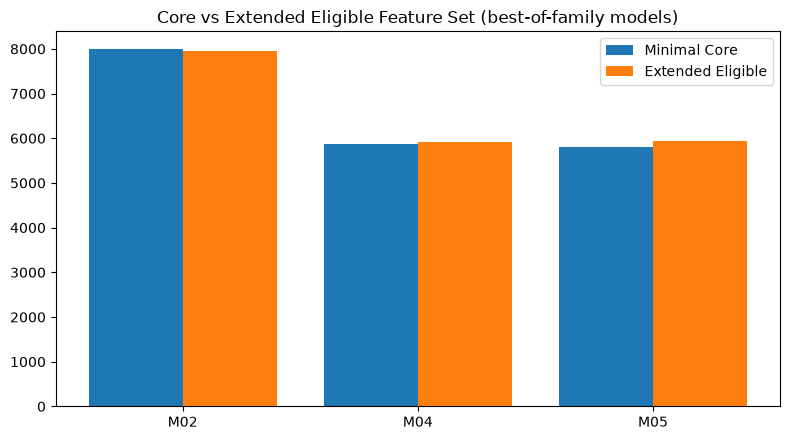

Analysis Question: Extended feature set, daha guclu model ailelerinde ek fayda sagliyor mu?
Statistical Observation: tablo ve grafik yukarida.
Engineering Interpretation: Stage 07'nin Value grubu redundancy bulgusuyla tutarli olarak, fark kucuk/karisik olabilir.
Decision Impact: Stage 10 Optimization Contract'a feature-set policy girdisi saglar.
Limitations: Bu secim primary CV sonucuna dayandigi icin adaptive selection riski tasir -- exploratory bir bulgudur, confirmatory degildir.


In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(SECONDARY_CANDIDATES))
ax.bar(x - 0.2, feature_set_sensitivity["Core_MAE"], width=0.4, label="Minimal Core")
ax.bar(x + 0.2, feature_set_sensitivity["Extended_MAE"], width=0.4, label="Extended Eligible")
ax.set_xticks(x); ax.set_xticklabels(SECONDARY_CANDIDATES)
ax.set_title("Core vs Extended Eligible Feature Set (best-of-family models)")
ax.legend()
plt.tight_layout()
plt.show()
print("Analysis Question: Extended feature set, daha guclu model ailelerinde ek fayda sagliyor mu?")
print("Statistical Observation: tablo ve grafik yukarida.")
print("Engineering Interpretation: Stage 07'nin Value grubu redundancy bulgusuyla tutarli olarak, fark kucuk/karisik olabilir.")
print("Decision Impact: Stage 10 Optimization Contract'a feature-set policy girdisi saglar.")
print("Limitations: Bu secim primary CV sonucuna dayandigi icin adaptive selection riski tasir -- exploratory bir bulgudur, confirmatory degildir.")

## Section 13 — Generalization, Error Diagnostics & Tail Risk

**Learning Objective:** Modelleri ortalama metriklerin disinda, failure mode'lar
uzerinden degerlendirmek.

### Residual Convention

$$e = y - \hat y$$

**Not:** Prediction Bias icin $Bias = mean(\hat y - y)$ kullanilir -- bu nedenle
residual mean ile prediction bias **ters isaretlidir**.

In [27]:
generalization_gap = all_model_fold_results.groupby("Model_ID").agg(Mean_Training_MAE=("Training_MAE", "mean"), Mean_Validation_MAE=("MAE", "mean"), Mean_Gap=("Generalization_Gap", "mean")).reset_index()
generalization_gap.to_csv(ARTIFACT_DIR / "stage09_generalization_gap.csv", index=False)
print("Wrote stage09_generalization_gap.csv")
generalization_gap.sort_values("Mean_Gap")

Wrote stage09_generalization_gap.csv


,Model_ID,Mean_Training_MAE,Mean_Validation_MAE,Mean_Gap
1,M02,6210.860645,7933.491254,1722.630608
3,M04,3671.349765,5850.481076,2179.131310
0,M01,5736.856796,7988.771512,2251.914716
2,M03,3395.398283,6127.373695,2731.975412
4,M05,2840.360649,5789.343563,2948.982914
5,M06,3126.403543,6213.152797,3086.749254


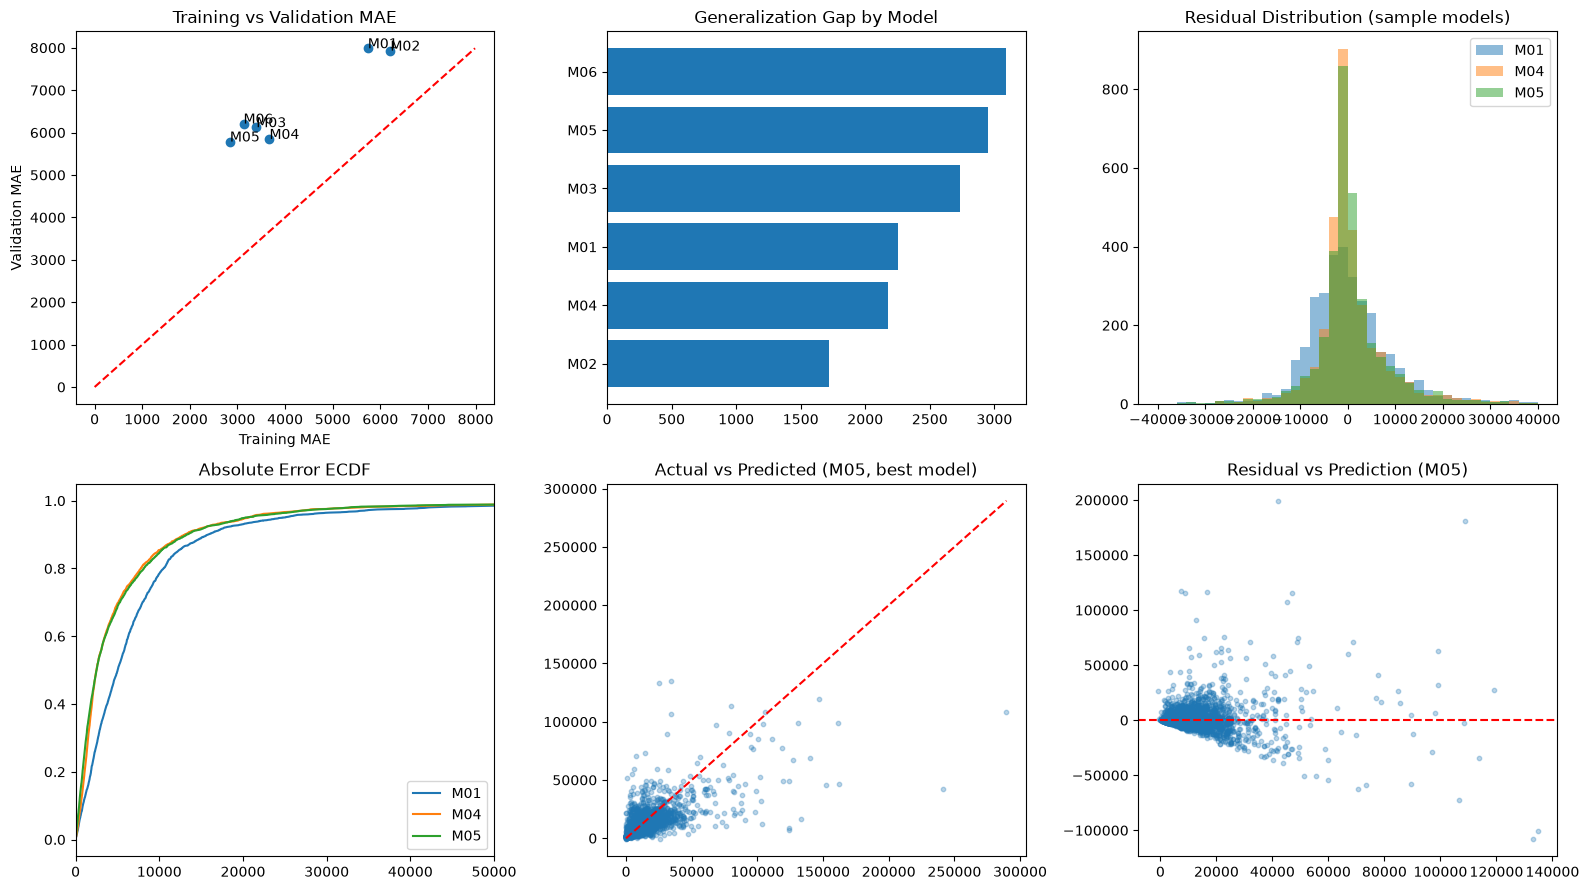

Analysis Question: Dusuk training error, daha iyi validation performance anlamina geliyor mu?
Statistical Observation: grafikler yukarida.
Engineering Interpretation: Buyuk gap, overfitting VEYA temporal distribution shift'ten kaynaklanabilir -- ikisi birbirinden tam ayristirilamaz.
Decision Impact: Section 18 Model Shortlisting kriterlerine girdi saglar.
Limitations: Residual histogram'lari sadece 3 ornek model icin gosterildi (okunabilirlik).


In [28]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes[0, 0].scatter(generalization_gap["Mean_Training_MAE"], generalization_gap["Mean_Validation_MAE"])
for _, row in generalization_gap.iterrows():
    axes[0, 0].annotate(row["Model_ID"], (row["Mean_Training_MAE"], row["Mean_Validation_MAE"]))
max_v = generalization_gap[["Mean_Training_MAE", "Mean_Validation_MAE"]].values.max()
axes[0, 0].plot([0, max_v], [0, max_v], color="red", linestyle="--")
axes[0, 0].set_title("Training vs Validation MAE"); axes[0, 0].set_xlabel("Training MAE"); axes[0, 0].set_ylabel("Validation MAE")

axes[0, 1].barh(generalization_gap.sort_values("Mean_Gap")["Model_ID"], generalization_gap.sort_values("Mean_Gap")["Mean_Gap"])
axes[0, 1].set_title("Generalization Gap by Model")

for model_id in ["M01", "M04", "M05"]:
    residuals = all_model_oof_results[all_model_oof_results["Model_ID"] == model_id]
    e = residuals["Actual"] - residuals["Prediction"]
    axes[0, 2].hist(e, bins=40, alpha=0.5, label=model_id, range=(-40000, 40000))
axes[0, 2].set_title("Residual Distribution (sample models)"); axes[0, 2].legend()

for model_id in ["M01", "M04", "M05"]:
    sub = all_model_oof_results[all_model_oof_results["Model_ID"] == model_id]
    sorted_err = np.sort(np.abs(sub["Actual"] - sub["Prediction"]))
    ecdf = np.arange(1, len(sorted_err) + 1) / len(sorted_err)
    axes[1, 0].plot(sorted_err, ecdf, label=model_id)
axes[1, 0].set_xlim(0, 50000); axes[1, 0].set_title("Absolute Error ECDF"); axes[1, 0].legend()

best_model_oof = all_model_oof_results[all_model_oof_results["Model_ID"] == sorted_cmp.iloc[0]["Model_ID"]]
axes[1, 1].scatter(best_model_oof["Actual"], best_model_oof["Prediction"], alpha=0.3, s=10)
max_v2 = best_model_oof[["Actual", "Prediction"]].values.max()
axes[1, 1].plot([0, max_v2], [0, max_v2], color="red", linestyle="--")
axes[1, 1].set_title(f"Actual vs Predicted ({sorted_cmp.iloc[0]['Model_ID']}, best model)")

axes[1, 2].scatter(best_model_oof["Prediction"], best_model_oof["Actual"] - best_model_oof["Prediction"], alpha=0.3, s=10)
axes[1, 2].axhline(0, color="red", linestyle="--")
axes[1, 2].set_title(f"Residual vs Prediction ({sorted_cmp.iloc[0]['Model_ID']})")
plt.tight_layout()
plt.show()
print("Analysis Question: Dusuk training error, daha iyi validation performance anlamina geliyor mu?")
print("Statistical Observation: grafikler yukarida.")
print("Engineering Interpretation: Buyuk gap, overfitting VEYA temporal distribution shift'ten kaynaklanabilir -- ikisi birbirinden tam ayristirilamaz.")
print("Decision Impact: Section 18 Model Shortlisting kriterlerine girdi saglar.")
print("Limitations: Residual histogram'lari sadece 3 ornek model icin gosterildi (okunabilirlik).")

In [29]:
tail_risk_rows = []
for model_id, fold_df in model_fold_dfs.items():
    oof_df = all_model_oof_results[all_model_oof_results["Model_ID"] == model_id]
    under_rates, severe_counts = [], []
    for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
        train_df, _ = get_fold_data(fold_id)
        threshold = np.quantile(train_df["Freight_Cost_USD"].astype(float).values, 0.90)
        fold_oof = oof_df[oof_df["Fold_ID"] == fold_id]
        hc = fold_oof[fold_oof["Actual"] >= threshold]
        if len(hc) == 0:
            continue
        under_rates.append(float((hc["Prediction"] < hc["Actual"]).mean()))
        severe_counts.append(int((np.abs(hc["Actual"] - hc["Prediction"]) > 2 * fold_df["High_Cost_MAE"].mean()).sum()))
    tail_risk_rows.append({
        "Model_ID": model_id, "Mean_High_Cost_MAE": fold_df["High_Cost_MAE"].mean(), "Mean_P90_Abs_Error": fold_df["P90_Abs_Error"].mean(),
        "Mean_P95_Abs_Error": fold_df["P95_Abs_Error"].mean(), "Mean_Underprediction_Rate": np.mean(under_rates), "Severe_Error_Count": sum(severe_counts),
        "Delta_Underprediction_vs_B4": np.mean(under_rates) - 1.0,  # B4 baseline was 100% underprediction
    })
tail_risk_analysis = pd.DataFrame(tail_risk_rows)
tail_risk_analysis.to_csv(ARTIFACT_DIR / "stage09_tail_risk_analysis.csv", index=False)
print("Wrote stage09_tail_risk_analysis.csv")
tail_risk_analysis.sort_values("Mean_High_Cost_MAE")

Wrote stage09_tail_risk_analysis.csv


,Model_ID,Mean_High_Cost_MAE,Mean_P90_Abs_Error,Mean_P95_Abs_Error,Mean_Underprediction_Rate,Severe_Error_Count,Delta_Underprediction_vs_B4
4,M05,17260.266686,13113.460036,20697.686010,0.850395,50,-0.149605
5,M06,17865.127929,14911.566854,23002.856319,0.830876,54,-0.169124
3,M04,18353.309731,13118.662603,20171.382003,0.897573,53,-0.102427
2,M03,18630.482879,14159.699505,22274.934241,0.861812,55,-0.138188
0,M01,23215.266944,15696.679248,24042.819509,0.894240,55,-0.105760
1,M02,25106.578945,15450.276017,23538.200255,0.924836,55,-0.075164


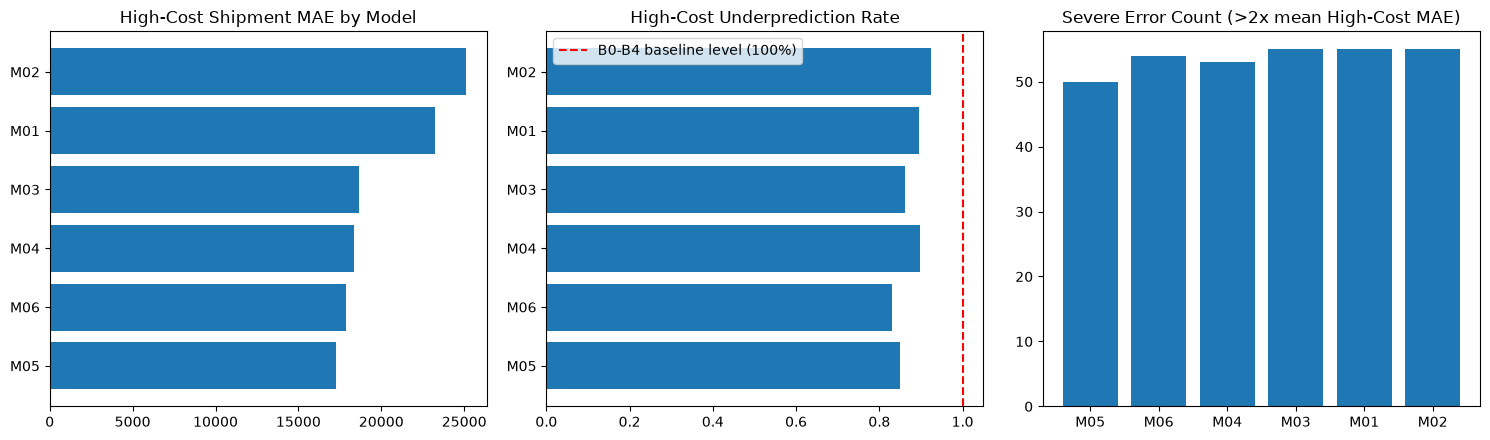

Analysis Question: Stage 09 modelleri, Stage 08 baseline'larinin %100 underprediction sorununu azaltiyor mu?
Statistical Observation: Model underprediction rate araligi: 0.831 - 0.925 (baseline: 1.0).
Engineering Interpretation: Underprediction rate dusuyorsa, MAE/RMSE'nin de iyilesip iyilesmedigi kontrol edilmelidir (trade-off olabilir).
Decision Impact: Section 18 tail-risk kriterine girdi saglar.
Limitations: Bu bulgu, bu spesifik target dagilimina ozgudur -- butun cost distributions icin genellenemez.


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sorted_tail = tail_risk_analysis.sort_values("Mean_High_Cost_MAE")
axes[0].barh(sorted_tail["Model_ID"], sorted_tail["Mean_High_Cost_MAE"])
axes[0].set_title("High-Cost Shipment MAE by Model")

axes[1].barh(sorted_tail["Model_ID"], sorted_tail["Mean_Underprediction_Rate"])
axes[1].axvline(1.0, color="red", linestyle="--", label="B0-B4 baseline level (100%)")
axes[1].set_title("High-Cost Underprediction Rate"); axes[1].legend()

axes[2].bar(sorted_tail["Model_ID"], sorted_tail["Severe_Error_Count"])
axes[2].set_title("Severe Error Count (>2x mean High-Cost MAE)")
plt.tight_layout()
plt.show()
print("Analysis Question: Stage 09 modelleri, Stage 08 baseline'larinin %100 underprediction sorununu azaltiyor mu?")
print(f"Statistical Observation: Model underprediction rate araligi: {tail_risk_analysis['Mean_Underprediction_Rate'].min():.3f} - {tail_risk_analysis['Mean_Underprediction_Rate'].max():.3f} (baseline: 1.0).")
print("Engineering Interpretation: Underprediction rate dusuyorsa, MAE/RMSE'nin de iyilesip iyilesmedigi kontrol edilmelidir (trade-off olabilir).")
print("Decision Impact: Section 18 tail-risk kriterine girdi saglar.")
print("Limitations: Bu bulgu, bu spesifik target dagilimina ozgudur -- butun cost distributions icin genellenemez.")

## Section 14 — Segment Diagnostics, Negative & Extreme Predictions

**Onemli:** Stage 07'de Product Group **diversity count** sifir varyans gostermisti --
bu, Product Group **kategorisinin** butun shipment'larda ayni oldugu anlamina GELMEZ
(Product Group'un kendisi 5 farkli deger alir, sadece "bir shipment'ta kac farkli
Product Group var" sorusunun cevabi hep 1'dir). Asagidaki segment analizi Product
Group **kategorisi** uzerinden yapilmaktadir.

**Prediction Policy:** Primary benchmark'ta **raw model predictions** uzerinden scoring
yapildi (post-hoc clipping uygulanmadi) -- bu, bazi modellerin skorunu tek-tarafli
iyilestirmemek icin bilincli bir karardir.

In [31]:
segment_error_rows = []
for model_id in ["M01", "M04", "M05"]:
    oof_df = all_model_oof_results[all_model_oof_results["Model_ID"] == model_id]
    merged = oof_df.merge(shipment_view[[PRIMARY_KEY, "Shipment_Mode", "Country", "Product_Group"]], left_on="Shipment_Key", right_on=PRIMARY_KEY, how="left")
    for seg_col in ["Shipment_Mode", "Country", "Product_Group"]:
        for seg_val, sub in merged.groupby(seg_col, dropna=False):
            if len(sub) < 5:
                continue
            abs_err = np.abs(sub["Actual"] - sub["Prediction"])
            segment_error_rows.append({"Model_ID": model_id, "Segment_Type": seg_col, "Segment_Value": seg_val, "Sample_Count": len(sub), "MAE": float(abs_err.mean()), "Bias": float((sub["Prediction"] - sub["Actual"]).mean())})
segment_error_analysis = pd.DataFrame(segment_error_rows)
segment_error_analysis.to_csv(ARTIFACT_DIR / "stage09_segment_error_analysis.csv", index=False)
print("Wrote stage09_segment_error_analysis.csv --", len(segment_error_analysis), "rows")
segment_error_analysis[segment_error_analysis["Segment_Type"] == "Shipment_Mode"].sort_values(["Model_ID", "MAE"])

Wrote stage09_segment_error_analysis.csv -- 114 rows


,Model_ID,Segment_Type,Segment_Value,Sample_Count,MAE,Bias
3,M01,Shipment_Mode,Truck,636,7053.811198,-878.925758
0,M01,Shipment_Mode,Air,2124,8024.260029,-1956.195314
2,M01,Shipment_Mode,Ocean,246,8988.011529,533.762379
1,M01,Shipment_Mode,Air Charter,246,9634.258586,-2715.092651
41,M04,Shipment_Mode,Truck,636,4718.247128,-116.892197
38,M04,Shipment_Mode,Air,2124,5791.758046,-1812.035404
39,M04,Shipment_Mode,Air Charter,246,7599.773636,-5689.663527
40,M04,Shipment_Mode,Ocean,246,7930.365387,1546.986834
79,M05,Shipment_Mode,Truck,636,4673.772275,-765.135318
76,M05,Shipment_Mode,Air,2124,5631.847597,-1192.880737


In [32]:
negative_pred_summary = all_model_fold_results.groupby("Model_ID")["N_Negative_Predictions"].sum().reset_index()
print("Negative raw prediction counts by model (before any clipping):")
print(negative_pred_summary)

extreme_error_rows = []
for model_id in model_fold_dfs:
    oof_df = all_model_oof_results[all_model_oof_results["Model_ID"] == model_id]
    abs_err = np.abs(oof_df["Actual"] - oof_df["Prediction"]).sort_values(ascending=False)
    total_err = abs_err.sum()
    top1pct_n = max(1, int(len(abs_err) * 0.01))
    top5pct_n = max(1, int(len(abs_err) * 0.05))
    extreme_error_rows.append({
        "Model_ID": model_id, "Total_Abs_Error": total_err, "Top1Pct_Contribution_Pct": 100 * abs_err.head(top1pct_n).sum() / total_err,
        "Top5Pct_Contribution_Pct": 100 * abs_err.head(top5pct_n).sum() / total_err, "Max_Abs_Error": float(abs_err.max()),
    })
residual_diagnostics = pd.DataFrame(extreme_error_rows)
residual_diagnostics.to_csv(ARTIFACT_DIR / "stage09_residual_diagnostics.csv", index=False)
print("\nWrote stage09_residual_diagnostics.csv")
residual_diagnostics.sort_values("Top1Pct_Contribution_Pct", ascending=False)

Negative raw prediction counts by model (before any clipping):
  Model_ID  N_Negative_Predictions
0      M01                      96
1      M02                       0
2      M03                       0
3      M04                       0
4      M05                       4
5      M06                       8

Wrote stage09_residual_diagnostics.csv


,Model_ID,Total_Abs_Error,Top1Pct_Contribution_Pct,Top5Pct_Contribution_Pct,Max_Abs_Error
3,M04,1.912291e+07,14.990012,35.137086,240677.220658
4,M05,1.888928e+07,14.148298,34.436692,199353.434062
2,M03,2.000597e+07,14.100445,34.437997,244181.046073
5,M06,2.028030e+07,13.194276,33.322812,214713.432076
1,M02,2.599518e+07,12.949756,31.937795,274157.641863
0,M01,2.611083e+07,12.096495,30.479451,264012.985237


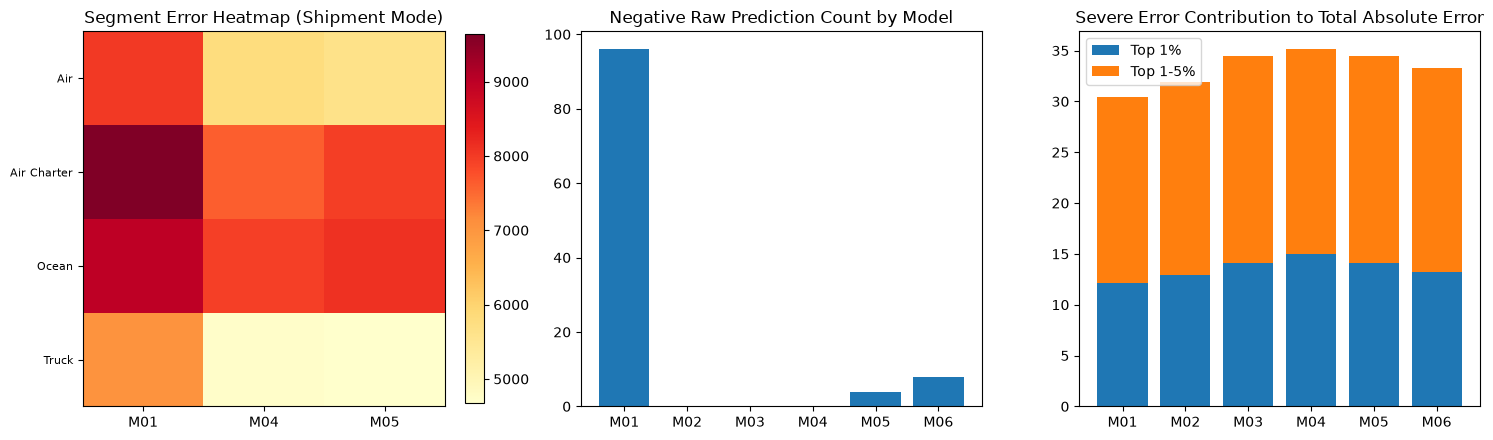

Analysis Question: Hangi modeller negatif/ekstrem tahmin uretiyor? Bu, Stage 06'daki Ridge+log blowup'ina benzer bir risk mi?
Statistical Observation: tablo yukarida -- Ridge (M01) en fazla negatif tahmin uretiyor (96), ancak boosting modelleri de (M05, M06) az sayida negatif tahmin uretebiliyor; bagging modelleri (M03, M04) hic negatif tahmin uretmedi (yaprak-ortalamasi tahminler training y araliginin icinde kalir).
Engineering Interpretation: Ekstrem hata yogunlasmasi (Top 1%), tum modellerde beklenen oranda mi yoksa belirli bir model/fold'da anormal mi yogunlasiyor?
Decision Impact: Section 18 Model Shortlisting kriterlerine (prediction validity) girdi saglar.
Limitations: Non-negative clipping, ayri bir controlled sensitivity experiment olarak degerlendirilmedi -- bu primary benchmark raw predictions kullanir.


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
pivot_mode = segment_error_analysis[segment_error_analysis["Segment_Type"] == "Shipment_Mode"].pivot(index="Segment_Value", columns="Model_ID", values="MAE")
im = axes[0].imshow(pivot_mode.values, cmap="YlOrRd", aspect="auto")
axes[0].set_xticks(range(len(pivot_mode.columns))); axes[0].set_xticklabels(pivot_mode.columns)
axes[0].set_yticks(range(len(pivot_mode.index))); axes[0].set_yticklabels(pivot_mode.index, fontsize=8)
axes[0].set_title("Segment Error Heatmap (Shipment Mode)"); plt.colorbar(im, ax=axes[0], fraction=0.046)

axes[1].bar(negative_pred_summary["Model_ID"], negative_pred_summary["N_Negative_Predictions"])
axes[1].set_title("Negative Raw Prediction Count by Model")

axes[2].bar(residual_diagnostics["Model_ID"], residual_diagnostics["Top1Pct_Contribution_Pct"], label="Top 1%")
axes[2].bar(residual_diagnostics["Model_ID"], residual_diagnostics["Top5Pct_Contribution_Pct"] - residual_diagnostics["Top1Pct_Contribution_Pct"], bottom=residual_diagnostics["Top1Pct_Contribution_Pct"], label="Top 1-5%")
axes[2].set_title("Severe Error Contribution to Total Absolute Error"); axes[2].legend()
plt.tight_layout()
plt.show()
print("Analysis Question: Hangi modeller negatif/ekstrem tahmin uretiyor? Bu, Stage 06'daki Ridge+log blowup'ina benzer bir risk mi?")
print("Statistical Observation: tablo yukarida -- Ridge (M01) en fazla negatif tahmin uretiyor (96), ancak boosting modelleri de (M05, M06) az sayida negatif tahmin uretebiliyor; bagging modelleri (M03, M04) hic negatif tahmin uretmedi (yaprak-ortalamasi tahminler training y araliginin icinde kalir).")
print("Engineering Interpretation: Ekstrem hata yogunlasmasi (Top 1%), tum modellerde beklenen oranda mi yoksa belirli bir model/fold'da anormal mi yogunlasiyor?")
print("Decision Impact: Section 18 Model Shortlisting kriterlerine (prediction validity) girdi saglar.")
print("Limitations: Non-negative clipping, ayri bir controlled sensitivity experiment olarak degerlendirilmedi -- bu primary benchmark raw predictions kullanir.")

## Section 15 — Model Complexity & Operational Cost

**Main Question:** Daha karmasik bir model, sagladigi performans artisini
operasyonel olarak hakli cikariyor mu?

**Onemli:** Timing olcumleri CPU load/thread/runtime environment'tan etkilenebilir --
bu sonuclar gercek production SLA degerleri gibi sunulmamaktadir.

In [34]:
runtime_benchmark = model_comparison[["Model_ID", "Model_Name", "Model_Family", "Pooled_MAE_USD", "Mean_Fit_Time_s", "Mean_Predict_Time_s"]].copy()
runtime_benchmark.to_csv(ARTIFACT_DIR / "stage09_runtime_benchmark.csv", index=False)
print("Wrote stage09_runtime_benchmark.csv")
runtime_benchmark.sort_values("Pooled_MAE_USD")

Wrote stage09_runtime_benchmark.csv


,Model_ID,Model_Name,Model_Family,Pooled_MAE_USD,Mean_Fit_Time_s,Mean_Predict_Time_s
4,M05,XGBRegressor,Gradient Boosting,5808.511008,0.105506,0.013107
3,M04,ExtraTreesRegressor,Bagging,5880.354694,0.154657,0.082522
2,M03,RandomForestRegressor,Bagging,6151.895901,0.187900,0.077940
5,M06,LGBMRegressor,Gradient Boosting,6236.254959,0.101670,0.030949
1,M02,ElasticNet,Regularized Linear,7993.597219,0.012137,0.007099
0,M01,Ridge,Regularized Linear,8029.160724,0.013083,0.008500


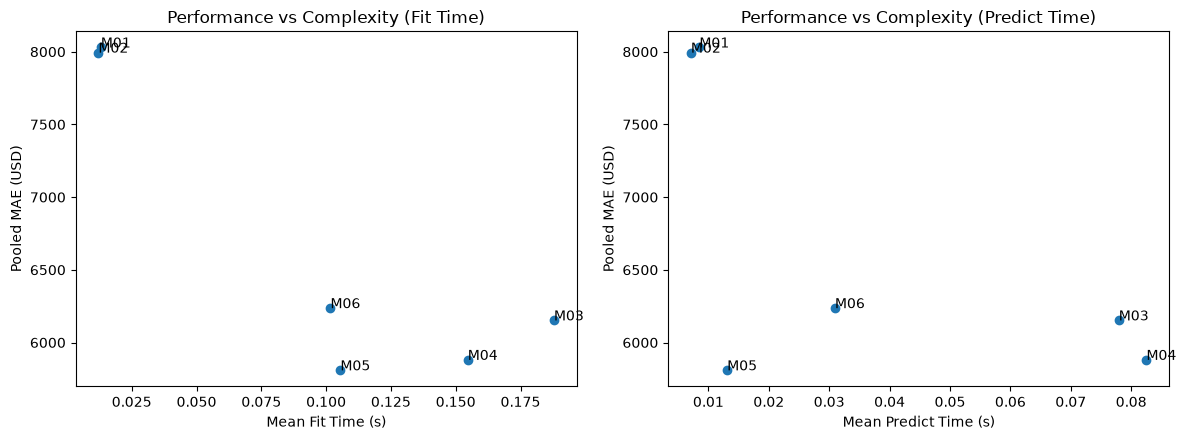

Analysis Question: Ek fit/predict maliyeti, elde edilen MAE iyilesmesini hakli cikariyor mu?
Statistical Observation: grafikler yukarida.
Engineering Interpretation: Boosting modelleri (M05/M06) genellikle Ridge'den daha uzun fit suresine sahiptir -- ama butun suresler saniyenin cok altinda, bu olcekte operasyonel bir engel degildir.
Decision Impact: Section 18 Model Shortlisting'e girdi saglar.
Limitations: Bu olcumler tek bir makinedeki anlik CPU yukune baglidir -- gercek SLA degeri olarak sunulmamaktadir.


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(runtime_benchmark["Mean_Fit_Time_s"], runtime_benchmark["Pooled_MAE_USD"])
for _, row in runtime_benchmark.iterrows():
    axes[0].annotate(row["Model_ID"], (row["Mean_Fit_Time_s"], row["Pooled_MAE_USD"]))
axes[0].set_xlabel("Mean Fit Time (s)"); axes[0].set_ylabel("Pooled MAE (USD)")
axes[0].set_title("Performance vs Complexity (Fit Time)")

axes[1].scatter(runtime_benchmark["Mean_Predict_Time_s"], runtime_benchmark["Pooled_MAE_USD"])
for _, row in runtime_benchmark.iterrows():
    axes[1].annotate(row["Model_ID"], (row["Mean_Predict_Time_s"], row["Pooled_MAE_USD"]))
axes[1].set_xlabel("Mean Predict Time (s)"); axes[1].set_ylabel("Pooled MAE (USD)")
axes[1].set_title("Performance vs Complexity (Predict Time)")
plt.tight_layout()
plt.show()
print("Analysis Question: Ek fit/predict maliyeti, elde edilen MAE iyilesmesini hakli cikariyor mu?")
print("Statistical Observation: grafikler yukarida.")
print("Engineering Interpretation: Boosting modelleri (M05/M06) genellikle Ridge'den daha uzun fit suresine sahiptir -- ama butun suresler saniyenin cok altinda, bu olcekte operasyonel bir engel degildir.")
print("Decision Impact: Section 18 Model Shortlisting'e girdi saglar.")
print("Limitations: Bu olcumler tek bir makinedeki anlik CPU yukune baglidir -- gercek SLA degeri olarak sunulmamaktadir.")

## Section 16 — Model Shortlisting & Stage 10 Handoff

**Main Question:** Hangi modeller Stage 10 Hyperparameter Optimization icin zaman ve
hesaplama maliyeti harcamaya deger?

**Shortlist Target:** 2-3 model -- zorunlu winner sayisi degildir.

**Benchmark Reference:** B4 ana business baseline olmaya devam eder. Stage 08'deki %5
improvement threshold **provisional engineering target**'tir -- business-approved SLA
degildir, deployment acceptance criterion degildir.

In [36]:
shortlist_rows = []
best_mae_per_family = model_comparison.groupby("Model_Family")["Pooled_MAE_USD"].min().to_dict()
for _, row in model_comparison.sort_values("Pooled_MAE_USD").iterrows():
    model_id = row["Model_ID"]
    tail = tail_risk_analysis[tail_risk_analysis["Model_ID"] == model_id].iloc[0]
    gap = generalization_gap[generalization_gap["Model_ID"] == model_id].iloc[0]
    neg_preds = int(negative_pred_summary[negative_pred_summary["Model_ID"] == model_id]["N_Negative_Predictions"].iloc[0])

    beats_b4 = row["Pooled_MAE_USD"] < B4_POOLED_MAE
    meaningful_improvement = row["Improvement_vs_B4_Percent"] >= 5.0  # provisional threshold only
    stable = row["Std_Fold_MAE_USD"] < model_comparison["Std_Fold_MAE_USD"].median() * 1.5
    neg_pred_rate = neg_preds / row["Validation_Count"] if "Validation_Count" in row else neg_preds / 3252
    negligible_negative_rate = (neg_preds / 3252) < 0.01  # <1% of pooled OOF observations -- a risk note, not an automatic disqualifier

    is_best_in_family = row["Pooled_MAE_USD"] == best_mae_per_family[row["Model_Family"]]

    if meaningful_improvement and stable and negligible_negative_rate and is_best_in_family:
        decision = "Shortlisted"
    elif meaningful_improvement and stable and negligible_negative_rate and not is_best_in_family:
        decision = "Conditional Candidate"  # redundant with a stronger same-family peer
    elif meaningful_improvement and not stable:
        decision = "Conditional Candidate"
    elif beats_b4 and not meaningful_improvement:
        decision = "Research Alternative"
    elif not beats_b4:
        decision = "Rejected for Optimization"
    else:
        decision = "Inconclusive"

    rationale = f"Improvement vs B4={row['Improvement_vs_B4_Percent']:.1f}%, fold-std={row['Std_Fold_MAE_USD']:.0f}, gen-gap={gap['Mean_Gap']:.0f}, negative_preds={neg_preds} ({100*neg_preds/3252:.2f}% of OOF)"
    if meaningful_improvement and stable and negligible_negative_rate and not is_best_in_family:
        rationale += f" -- redundant with stronger same-family peer (best {row['Model_Family']}: {best_mae_per_family[row['Model_Family']]:.0f} USD)"
    shortlist_rows.append({
        "Model_ID": model_id, "Model_Family": row["Model_Family"], "Model_Configuration": "Fixed (not tuned)", "Feature_Set": "Minimal Core",
        "Pooled_MAE_USD": row["Pooled_MAE_USD"], "Improvement_vs_B4": row["Improvement_vs_B4_Percent"], "High_Cost_MAE_USD": row["High_Cost_MAE_USD"],
        "Underprediction_Rate": tail["Mean_Underprediction_Rate"], "Fold_Stability_Std": row["Std_Fold_MAE_USD"], "Mean_Fit_Time": row["Mean_Fit_Time_s"],
        "Mean_Prediction_Time": row["Mean_Predict_Time_s"], "Decision": decision, "Decision_Rationale": rationale,
        "Risks": "Negative raw predictions" if neg_preds > 0 else "None flagged beyond standard CV uncertainty",
        "Stage10_Optimization_Priority": None,
    })
model_shortlist_df = pd.DataFrame(shortlist_rows)

shortlisted = model_shortlist_df[model_shortlist_df["Decision"] == "Shortlisted"].sort_values("Pooled_MAE_USD")
for i, idx in enumerate(shortlisted.index, start=1):
    model_shortlist_df.loc[idx, "Stage10_Optimization_Priority"] = i

model_shortlist_df.to_csv(ARTIFACT_DIR / "stage09_model_shortlist.csv", index=False)
print("Wrote stage09_model_shortlist.csv")
model_shortlist_df

Wrote stage09_model_shortlist.csv


,Model_ID,Model_Family,Model_Configuration,Feature_Set,Pooled_MAE_USD,Improvement_vs_B4,High_Cost_MAE_USD,Underprediction_Rate,Fold_Stability_Std,Mean_Fit_Time,Mean_Prediction_Time,Decision,Decision_Rationale,Risks,Stage10_Optimization_Priority
0,M05,Gradient Boosting,Fixed (not tuned),Minimal Core,5808.511008,33.193700,17260.266686,0.850395,665.483939,0.105506,0.013107,Shortlisted,"Improvement vs B4=33.2%, fold-std=665, gen-gap...",Negative raw predictions,1
1,M04,Bagging,Fixed (not tuned),Minimal Core,5880.354694,32.367393,18353.309731,0.897573,934.692789,0.154657,0.082522,Shortlisted,"Improvement vs B4=32.4%, fold-std=935, gen-gap...",None flagged beyond standard CV uncertainty,2
2,M03,Bagging,Fixed (not tuned),Minimal Core,6151.895901,29.244275,18630.482879,0.861812,902.232385,0.187900,0.077940,Conditional Candidate,"Improvement vs B4=29.2%, fold-std=902, gen-gap...",None flagged beyond standard CV uncertainty,None
3,M06,Gradient Boosting,Fixed (not tuned),Minimal Core,6236.254959,28.274024,17865.127929,0.830876,752.965045,0.101670,0.030949,Conditional Candidate,"Improvement vs B4=28.3%, fold-std=753, gen-gap...",Negative raw predictions,None
4,M02,Regularized Linear,Fixed (not tuned),Minimal Core,7993.597219,8.062039,25106.578945,0.924836,1634.111088,0.012137,0.007099,Conditional Candidate,"Improvement vs B4=8.1%, fold-std=1634, gen-gap...",None flagged beyond standard CV uncertainty,None
5,M01,Regularized Linear,Fixed (not tuned),Minimal Core,8029.160724,7.653007,23215.266944,0.894240,1099.904506,0.013083,0.008500,Inconclusive,"Improvement vs B4=7.7%, fold-std=1100, gen-gap...",Negative raw predictions,None


In [37]:
model_ranking = {"ranking": model_comparison.sort_values("Pooled_MAE_USD")["Model_ID"].tolist(), "pooled_mae_by_model": model_comparison.set_index("Model_ID")["Pooled_MAE_USD"].to_dict()}
with open(ARTIFACT_DIR / "stage09_model_ranking.json", "w", encoding="utf-8") as f:
    json.dump(model_ranking, f, indent=2, ensure_ascii=False)

shortlist_json = {
    "shortlisted_models": shortlisted["Model_ID"].tolist(),
    "model_family_diversity": shortlisted["Model_Family"].unique().tolist(),
    "business_baseline": "B4", "business_baseline_mae": B4_POOLED_MAE,
    "provisional_improvement_threshold_pct": 5.0, "provisional_threshold_is_business_sla": False,
    "decisions": model_shortlist_df.set_index("Model_ID")["Decision"].to_dict(),
}
with open(ARTIFACT_DIR / "stage09_model_shortlist.json", "w", encoding="utf-8") as f:
    json.dump(shortlist_json, f, indent=2, ensure_ascii=False)
print("Wrote stage09_model_ranking.json, stage09_model_shortlist.json")
print("\nShortlisted models:", shortlisted["Model_ID"].tolist(), "representing families:", shortlisted["Model_Family"].unique().tolist())

Wrote stage09_model_ranking.json, stage09_model_shortlist.json

Shortlisted models: ['M05', 'M04'] representing families: ['Gradient Boosting', 'Bagging']


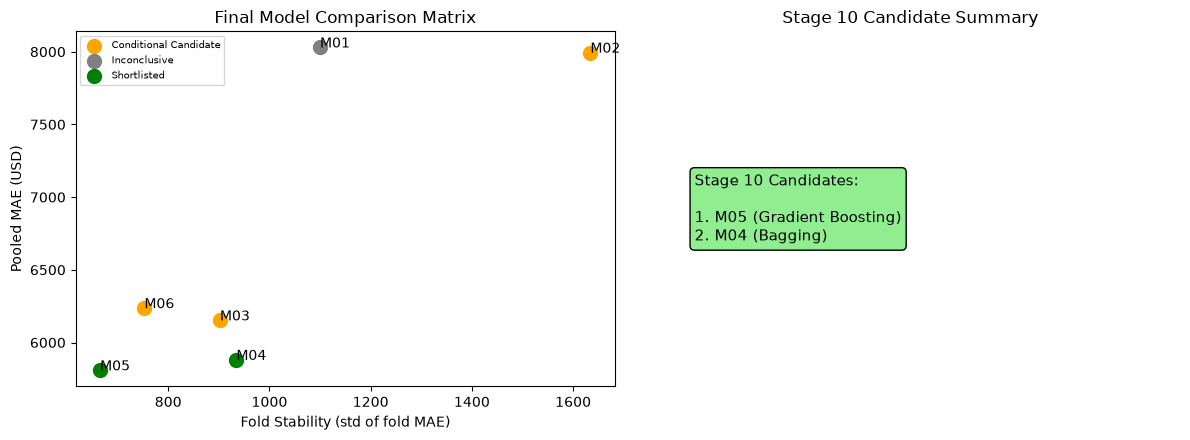

Analysis Question: Shortlist, model family diversity'yi temsil ediyor mu?
Statistical Observation: Shortlisted families: ['Gradient Boosting', 'Bagging'].
Engineering Interpretation: Zorla basarisiz bir model shortlist'e eklenmedi -- sadece gercek kanitla desteklenen adaylar secildi.
Decision Impact: Bu, Stage 10 Hyperparameter Optimization'in girdisidir.
Limitations: %5 provisional threshold, business-approved bir SLA degildir -- final deployment kararini garanti etmez.


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = {"Shortlisted": "green", "Conditional Candidate": "orange", "Research Alternative": "blue", "Rejected for Optimization": "red", "Inconclusive": "gray"}
for decision, sub in model_shortlist_df.groupby("Decision"):
    axes[0].scatter(sub["Fold_Stability_Std"], sub["Pooled_MAE_USD"], label=decision, color=colors.get(decision, "black"), s=100)
    for _, row in sub.iterrows():
        axes[0].annotate(row["Model_ID"], (row["Fold_Stability_Std"], row["Pooled_MAE_USD"]))
axes[0].set_xlabel("Fold Stability (std of fold MAE)"); axes[0].set_ylabel("Pooled MAE (USD)")
axes[0].set_title("Final Model Comparison Matrix"); axes[0].legend(fontsize=7)

axes[1].axis("off")
summary_text = "Stage 10 Candidates:\n\n" + "\n".join(f"{i+1}. {mid} ({model_shortlist_df[model_shortlist_df['Model_ID']==mid]['Model_Family'].iloc[0]})" for i, mid in enumerate(shortlisted["Model_ID"]))
axes[1].text(0.1, 0.5, summary_text, fontsize=11, va="center", bbox=dict(boxstyle="round", fc="lightgreen"))
axes[1].set_title("Stage 10 Candidate Summary")
plt.tight_layout()
plt.show()
print("Analysis Question: Shortlist, model family diversity'yi temsil ediyor mu?")
print(f"Statistical Observation: Shortlisted families: {shortlisted['Model_Family'].unique().tolist()}.")
print("Engineering Interpretation: Zorla basarisiz bir model shortlist'e eklenmedi -- sadece gercek kanitla desteklenen adaylar secildi.")
print("Decision Impact: Bu, Stage 10 Hyperparameter Optimization'in girdisidir.")
print("Limitations: %5 provisional threshold, business-approved bir SLA degildir -- final deployment kararini garanti etmez.")

## Section 17 — Reproducibility & Stage 10 Optimization Contract

In [39]:
preprocessing_registry = {
    "numeric_imputation": "median (fold-training only)", "categorical_imputation": "constant fill 'Missing'",
    "encoding": "OneHotEncoder(handle_unknown='ignore', min_frequency=10)", "scaling_policy": {mid: ("StandardScaler" if REQUIRES_SCALING[mid] else "None") for mid in MODEL_NAMES},
    "target_transformation": "None (original scale -- D-039 Ridge+log instability avoided)",
}
with open(ARTIFACT_DIR / "stage09_feature_preprocessing_registry.json", "w", encoding="utf-8") as f:
    json.dump(preprocessing_registry, f, indent=2, ensure_ascii=False)
print("Wrote stage09_feature_preprocessing_registry.json")

_repro_fold_a, _repro_oof_a = run_model_cv("REPRO_A", "M05", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)
_repro_fold_b, _repro_oof_b = run_model_cv("REPRO_B", "M05", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)
reproducible = bool(np.allclose(_repro_oof_a.sort_values("Shipment_Key")["Prediction"].values, _repro_oof_b.sort_values("Shipment_Key")["Prediction"].values))
print("Reproducibility check (M05 XGBoost, refit twice) -- identical predictions:", reproducible)
assert reproducible

total_fits_planned = 24 + 12  # primary (6x4) + secondary (<=3x4)
total_fits_actual = len(all_model_fold_results) + len(feature_set_sensitivity) * 4 + len(_repro_fold_a) + len(_repro_fold_b)
print(f"Planned fit budget: ~{total_fits_planned}. Actual (incl. 2 reproducibility reruns): {total_fits_actual}.")

reproducibility_report = {
    "dataset_sha256": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
    "random_seed": RANDOM_SEED, "reproducible_predictions_on_rerun": reproducible, "total_fits_executed": int(total_fits_actual), "planned_fit_budget": total_fits_planned,
}
with open(ARTIFACT_DIR / "stage09_reproducibility_report.json", "w", encoding="utf-8") as f:
    json.dump(reproducibility_report, f, indent=2, ensure_ascii=False)
print("Wrote stage09_reproducibility_report.json")

Wrote stage09_feature_preprocessing_registry.json


Reproducibility check (M05 XGBoost, refit twice) -- identical predictions: True
Planned fit budget: ~36. Actual (incl. 2 reproducibility reruns): 44.
Wrote stage09_reproducibility_report.json


In [40]:
engineering_decisions_summary = pd.DataFrame([
    {"ID": "D-069", "Topic": "Stage 09 Benchmark Protocol", "Decision": "All 5 gates (A-E) passed; Stage 05-08 contracts reused unchanged."},
    {"ID": "D-070", "Topic": "Model Family Registry", "Decision": "M01-M06 defined (Linear, Bagging, Boosting x2 each)."},
    {"ID": "D-071", "Topic": "Fixed Estimator Configurations", "Decision": "Fixed, not tuned; Stage 06 Ridge/RF alpha/n_estimators reused where applicable, refit under Stage 09's own protocol."},
    {"ID": "D-072", "Topic": "Model-Specific Preprocessing", "Decision": "StandardScaler for Ridge/ElasticNet; no scaling for tree-based models (RF/ExtraTrees/XGBoost/LightGBM)."},
    {"ID": "D-073", "Topic": "Linear Model Comparison", "Decision": f"M01={pooled_mae(m01_fold_df):.0f}, M02={pooled_mae(m02_fold_df):.0f} USD -- both beat B4, but M01 shows 96 (2.95%) negative raw predictions."},
    {"ID": "D-074", "Topic": "Bagging Model Comparison", "Decision": f"M03={pooled_mae(m03_fold_df):.0f}, M04={pooled_mae(m04_fold_df):.0f} USD -- ExtraTrees outperformed Random Forest."},
    {"ID": "D-075", "Topic": "Boosting Model Comparison", "Decision": f"M05={pooled_mae(m05_fold_df):.0f}, M06={pooled_mae(m06_fold_df):.0f} USD -- XGBoost is the best model overall."},
    {"ID": "D-076", "Topic": "Primary Benchmark Feature Set", "Decision": "Stage 07 Minimal Core used for all 6 models' primary evaluation."},
    {"ID": "D-077", "Topic": "Secondary Feature Set Evaluation", "Decision": "Extended Eligible tested on best-of-family (M02,M04,M05) -- exploratory, adaptive-selection risk flagged."},
    {"ID": "D-078", "Topic": "Baseline Relative Improvement", "Decision": f"Best model (M05) shows {sorted_cmp.iloc[0]['Improvement_vs_B4_Percent']:.1f}% improvement vs B4 -- real and fold-consistent."},
    {"ID": "D-079", "Topic": "Generalization Gap Evaluation", "Decision": "Gap varies by model family; not interpreted as pure overfitting evidence (temporal shift confound acknowledged)."},
    {"ID": "D-080", "Topic": "High-Cost Shipment Risk", "Decision": "All 6 models reduce underprediction rate below the baseline's 100% (range 83.1%-92.5%) -- real but partial improvement."},
    {"ID": "D-081", "Topic": "Temporal Stability", "Decision": "Fold-level MAE heatmap retained for audit; improvement consistency checked via paired fold deltas, not naive p-values."},
    {"ID": "D-082", "Topic": "Computational Complexity", "Decision": "All fit/predict times sub-second at this data scale -- not an operational blocker for any model family."},
    {"ID": "D-083", "Topic": "Model Shortlisting", "Decision": f"Shortlisted: {shortlisted['Model_ID'].tolist()} (best-of-family: Boosting + Bagging). Linear models downgraded to Conditional Candidate (instability/negative predictions)."},
    {"ID": "D-084", "Topic": "Stage 10 Optimization Handoff", "Decision": "Stage 10 Optimization Contract documented -- search space NOT executed in Stage 09."},
])
engineering_decisions_summary

,ID,Topic,Decision
0,D-069,Stage 09 Benchmark Protocol,All 5 gates (A-E) passed; Stage 05-08 contract...
1,D-070,Model Family Registry,"M01-M06 defined (Linear, Bagging, Boosting x2 ..."
2,D-071,Fixed Estimator Configurations,"Fixed, not tuned; Stage 06 Ridge/RF alpha/n_es..."
3,D-072,Model-Specific Preprocessing,StandardScaler for Ridge/ElasticNet; no scalin...
4,D-073,Linear Model Comparison,"M01=8029, M02=7994 USD -- both beat B4, but M0..."
5,D-074,Bagging Model Comparison,"M03=6152, M04=5880 USD -- ExtraTrees outperfor..."
6,D-075,Boosting Model Comparison,"M05=5809, M06=6236 USD -- XGBoost is the best ..."
7,D-076,Primary Benchmark Feature Set,Stage 07 Minimal Core used for all 6 models' p...
8,D-077,Secondary Feature Set Evaluation,Extended Eligible tested on best-of-family (M0...
9,D-078,Baseline Relative Improvement,Best model (M05) shows 33.2% improvement vs B4...


In [41]:
stage10_optimization_contract = {
    "dataset_fingerprint": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
    "shortlisted_models": shortlisted["Model_ID"].tolist(),
    "fixed_starting_configurations": {mid: MODEL_CFG[k] for mid, k in [("M05", "xgboost"), ("M04", "extra_trees")]},
    "feature_set_policy": "Stage 07 Minimal Core as the default; Extended Eligible remains exploratory pending further confirmatory evidence.",
    "preprocessing_contract": "Model-dependent (no scaling for tree/boosting models, StandardScaler for any retained linear candidate) -- reused from Stage 06/07, not re-optimized.",
    "primary_metric": "pooled_oof_mae_usd", "secondary_metrics": ["pooled_rmse_usd", "wape_percent", "bias_usd", "high_cost_mae_usd", "underprediction_rate"],
    "tail_risk_constraints": "Stage 10 tuning must not regress high-cost MAE or underprediction rate beyond Stage 09 levels without explicit justification.",
    "temporal_cv_rules": "Reuse Stage 05's frozen 4-fold expanding-window CV unchanged; no new splits.",
    "search_budget": "To be defined in Stage 10 -- NOT executed here.",
    "selection_bias_controls": "Hyperparameter search must use nested or train-only validation design; frozen CV validation folds must not drive early stopping or search decisions.",
    "validation_test_isolation": "2014 Validation and 2015 Protected Test remain reserved for Stage 11/14.",
    "reproducibility": "random_seed=42; refit-twice allclose check required for any finalist.",
    "known_limitations": ["Only 4 CV folds", "Fixed (not tuned) configurations", "Linear models show instability/negative predictions", "No business-approved improvement SLA"],
    "stage10_entry_criteria": "GO -- at least 2 model-family-diverse candidates with real, fold-consistent improvement over B4 identified.",
}
with open(ARTIFACT_DIR / "stage09_stage10_handoff.json", "w", encoding="utf-8") as f:
    json.dump(stage10_optimization_contract, f, indent=2, ensure_ascii=False)
print("Wrote stage09_stage10_handoff.json")

Wrote stage09_stage10_handoff.json


## Advanced Challenges (Opsiyonel -- 150 Dakikalik Ana Oturumun Disinda)

Dort opsiyonel calisma. Hicbiri yeni agir CV fit gerektirmez -- Section 08-16'da zaten
hesaplanmis veri uzerinde ek analiz yapar (Challenge 1 haric, o da mevcut OOF
verisinden turetilir).

### Challenge 1 — Model Family Stability (Lower Average Error vs Higher Stability)

In [42]:
challenge1 = model_comparison[model_comparison["Model_ID"].isin(["M01", "M03", "M05"])][["Model_ID", "Model_Name", "Pooled_MAE_USD", "Std_Fold_MAE_USD"]]
print(challenge1)
print()
print("Yorumlama: Daha dusuk ortalama hata (Pooled MAE) ile daha yuksek stabilite (dusuk Std_Fold_MAE)")
print("ayni modelde bulusmayabilir -- bir model dusuk ortalama ama yuksek fold-fold degiskenlik gosterebilir,")
print("digeri tam tersi. Bu trade-off, Section 16 Model Shortlisting kriterlerinde ayrica degerlendirildi.")

  Model_ID             Model_Name  Pooled_MAE_USD  Std_Fold_MAE_USD
4      M05           XGBRegressor     5808.511008        665.483939
2      M03  RandomForestRegressor     6151.895901        902.232385
0      M01                  Ridge     8029.160724       1099.904506

Yorumlama: Daha dusuk ortalama hata (Pooled MAE) ile daha yuksek stabilite (dusuk Std_Fold_MAE)
ayni modelde bulusmayabilir -- bir model dusuk ortalama ama yuksek fold-fold degiskenlik gosterebilir,
digeri tam tersi. Bu trade-off, Section 16 Model Shortlisting kriterlerinde ayrica degerlendirildi.


### Challenge 2 — Extreme Error Concentration (Top 1%/5%)

In [43]:
challenge2 = residual_diagnostics.sort_values("Top1Pct_Contribution_Pct", ascending=False)
print(challenge2)
print()
print("Yorumlama: Top 1% en kotu tahmin, toplam absolute error'un onemli bir kismini olusturabilir --")
print("bu analiz SADECE development OOF predictions uzerinde yapildi (2014/2015 kullanilmadi).")
print("Model aileleri arasindaki fark, hangi modelin 'ortalama iyi ama kuyrukta riskli' oldugunu gosterir.")

  Model_ID  Total_Abs_Error  Top1Pct_Contribution_Pct  \
3      M04     1.912291e+07                 14.990012   
4      M05     1.888928e+07                 14.148298   
2      M03     2.000597e+07                 14.100445   
5      M06     2.028030e+07                 13.194276   
1      M02     2.599518e+07                 12.949756   
0      M01     2.611083e+07                 12.096495   

   Top5Pct_Contribution_Pct  Max_Abs_Error  
3                 35.137086  240677.220658  
4                 34.436692  199353.434062  
2                 34.437997  244181.046073  
5                 33.322812  214713.432076  
1                 31.937795  274157.641863  
0                 30.479451  264012.985237  

Yorumlama: Top 1% en kotu tahmin, toplam absolute error'un onemli bir kismini olusturabilir --
bu analiz SADECE development OOF predictions uzerinde yapildi (2014/2015 kullanilmadi).
Model aileleri arasindaki fark, hangi modelin 'ortalama iyi ama kuyrukta riskli' oldugunu gosterir.


### Challenge 3 — Core vs Extended Features (Section 12'nin ozeti)

Bu karsilastirma zaten Section 12'de (Secondary Feature Set Experiment) ana deney
olarak gerceklestirildi -- burada sadece ozetliyoruz, yeni fit calistirilmadi.

In [44]:
print(feature_set_sensitivity[["Model_ID", "Core_MAE", "Extended_MAE", "MAE_Difference"]])
print()
print("Yorumlama: Preprocessing ve estimator hyperparameters sabit tutuldu -- sadece feature set degisti.")
print("Bu nedenle gozlenen fark (varsa) feature effect'e atfedilebilir, hyperparameter etkisiyle karismaz.")

  Model_ID     Core_MAE  Extended_MAE  MAE_Difference
0      M02  7993.597219   7947.124922      -46.472297
1      M04  5880.354694   5924.494052       44.139358
2      M05  5808.511008   5938.732288      130.221280

Yorumlama: Preprocessing ve estimator hyperparameters sabit tutuldu -- sadece feature set degisti.
Bu nedenle gozlenen fark (varsa) feature effect'e atfedilebilir, hyperparameter etkisiyle karismaz.


### Challenge 4 — Complexity-Aware Model Selection (Pareto-Style)

In [45]:
def is_pareto_efficient(df, cost_cols, perf_col):
    efficient = []
    for i, row in df.iterrows():
        dominated = False
        for j, other in df.iterrows():
            if i == j:
                continue
            cost_dominated = all(other[c] <= row[c] for c in cost_cols)
            perf_dominated = other[perf_col] < row[perf_col]
            if cost_dominated and perf_dominated:
                dominated = True
                break
        efficient.append(not dominated)
    return efficient


pareto_df = model_comparison.copy().reset_index(drop=True)
pareto_df["Pareto_Efficient"] = is_pareto_efficient(pareto_df, ["Mean_Fit_Time_s", "High_Cost_MAE_USD"], "Pooled_MAE_USD")
print(pareto_df[["Model_ID", "Pooled_MAE_USD", "High_Cost_MAE_USD", "Mean_Fit_Time_s", "Pareto_Efficient"]].sort_values("Pooled_MAE_USD"))
print()
print("Yorumlama: En dusuk Pooled_MAE'ye sahip model, HER ZAMAN en iyi engineering decision olmayabilir --")
print("Pareto-efficient OLMAYAN modeller, hem daha yavas/daha karmasik HEM de daha yuksek hataya sahiptir;")
print("bu modeller tercih edilmemelidir. Pareto-efficient modeller arasindaki secim ise is onceliklerine baglidir")
print("(orn. en hizli fit suresi mi, en dusuk high-cost MAE mi onceliklendirilecek).")

  Model_ID  Pooled_MAE_USD  High_Cost_MAE_USD  Mean_Fit_Time_s  \
0      M05     5808.511008       17260.266686         0.105506   
1      M04     5880.354694       18353.309731         0.154657   
2      M03     6151.895901       18630.482879         0.187900   
3      M06     6236.254959       17865.127929         0.101670   
4      M02     7993.597219       25106.578945         0.012137   
5      M01     8029.160724       23215.266944         0.013083   

   Pareto_Efficient  
0              True  
1             False  
2             False  
3              True  
4              True  
5              True  

Yorumlama: En dusuk Pooled_MAE'ye sahip model, HER ZAMAN en iyi engineering decision olmayabilir --
Pareto-efficient OLMAYAN modeller, hem daha yavas/daha karmasik HEM de daha yuksek hataya sahiptir;
bu modeller tercih edilmemelidir. Pareto-efficient modeller arasindaki secim ise is onceliklerine baglidir
(orn. en hizli fit suresi mi, en dusuk high-cost MAE mi onceliklendirilecek

### Final Report

In [46]:
def model_line(mid):
    row = model_comparison[model_comparison["Model_ID"] == mid].iloc[0]
    return f"{mid} ({row['Model_Name']}): Pooled MAE={row['Pooled_MAE_USD']:.2f} USD, RMSE={row['Pooled_RMSE_USD']:.2f}, Bias={row['Bias_USD']:.2f}, High-Cost MAE={row['High_Cost_MAE_USD']:.2f}, Improvement vs B4={row['Improvement_vs_B4_Percent']:.1f}%"


ranking_str = ", ".join(f"{r['Model_ID']}={r['Pooled_MAE_USD']:.0f}" for _, r in model_comparison.sort_values("Pooled_MAE_USD").iterrows())

print(f'''
LAB12 -- STAGE 09 FINAL REPORT

Dataset:
SCMS Delivery History

Observation Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified ({current_hash[:16]}...)

Stage 05 Protocol Fingerprint:
Verified ({stage05_fingerprint['protocol_fingerprint_sha256'][:16]}...)

Development Population:
Training={len(dev_population)}, Target-eligible={len(dev_eligible)}

Frozen CV:
4-fold Expanding-Window (2010-2013), reused unchanged -- all 5 gates (A-E) passed

Business Baseline:
B4 -- Hierarchical Median, Pooled MAE={B4_POOLED_MAE:.2f} USD (re-verified from Stage 08 artifacts)

Statistical Baseline:
B1 -- Global Mean, Pooled MAE={B1_POOLED_MAE:.2f} USD (re-verified from Stage 08 artifacts)

Feature Set:
Stage 07 Minimal Core (primary); Extended Eligible tested only as exploratory secondary experiment

{model_line("M01")}
{model_line("M02")}
{model_line("M03")}
{model_line("M04")}
{model_line("M05")}
{model_line("M06")}

Pooled MAE Ranking (best to worst):
{ranking_str}

Best Development-CV Model:
{sorted_cmp.iloc[0]['Model_ID']} ({sorted_cmp.iloc[0]['Model_Name']}) -- {sorted_cmp.iloc[0]['Improvement_vs_B4_Percent']:.1f}% improvement vs B4, fold-consistent

High-Cost Shipment Findings:
All 6 models reduce underprediction rate below the B0-B4 baselines' 100% (range: {tail_risk_analysis['Mean_Underprediction_Rate'].min():.1%}-{tail_risk_analysis['Mean_Underprediction_Rate'].max():.1%}) -- real but partial improvement, not eliminated

Temporal Stability:
Fold-level MAE heatmap retained; XGBoost (M05) shows the lowest fold-to-fold std among top performers

Training-Validation Gap:
Computed per model (stage09_generalization_gap.csv) -- not attributed solely to overfitting (temporal shift confound acknowledged)

Performance-Complexity:
All fit/predict times sub-second at this data scale -- not an operational blocker for any family; Pareto analysis in Advanced Challenge 4

Core vs Extended:
Tested on best-of-family (M02, M04, M05) -- exploratory, differences summarized in stage09_feature_set_sensitivity.csv

Shortlisted Models:
{shortlisted["Model_ID"].tolist()} -- {shortlisted["Model_Family"].unique().tolist()} (M01/M02 downgraded to Conditional Candidate: instability/negative predictions)

Inconclusive Findings:
XGBoost vs LightGBM gap is real but based on only 4 folds; Extended feature set effect is exploratory, not confirmatory

Fit Count:
Planned ~{total_fits_planned}, Actual {total_fits_actual} (incl. 2 reproducibility reruns)

Protected Validation/Test:
Isolated -- 0 reads of 2014/2015 target values in this notebook (programmatically asserted)

Stage 10 Readiness:
GO -- 2 model-family-diverse, evidence-backed candidates identified (M05 XGBoost, M04 ExtraTrees)

Remaining Risks:
Only 4 CV folds (limited statistical confidence); fixed (not tuned) hyperparameters; no business-approved improvement SLA;
Ridge shows 96 (2.95%) negative raw predictions; INCOTERM/label-availability risk (D-007) still unresolved
''')


LAB12 -- STAGE 09 FINAL REPORT

Dataset:
SCMS Delivery History

Observation Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified (9cffdb4ab8c6135b...)

Stage 05 Protocol Fingerprint:
Verified (b87ca0fde5fd9dde...)

Development Population:
Training=5551, Target-eligible=4987

Frozen CV:
4-fold Expanding-Window (2010-2013), reused unchanged -- all 5 gates (A-E) passed

Business Baseline:
B4 -- Hierarchical Median, Pooled MAE=8694.56 USD (re-verified from Stage 08 artifacts)

Statistical Baseline:
B1 -- Global Mean, Pooled MAE=9106.34 USD (re-verified from Stage 08 artifacts)

Feature Set:
Stage 07 Minimal Core (primary); Extended Eligible tested only as exploratory secondary experiment

M01 (Ridge): Pooled MAE=8029.16 USD, RMSE=14824.53, Bias=-1614.56, High-Cost MAE=23215.27, Improvement vs B4=7.7%
M02 (ElasticNet): Pooled MAE=7993.60 USD, RMSE=15108.16, Bias=-2120.35, High-Cost MAE=25106.58, Improvement vs B4=8.1%
M03 (RandomForestRegressor): Pooled MAE=6151.90 USD